In [1]:
# Hafta 9


# Konu: Sıfırdan Tokenizer


# Görevler:
    ## Görev 1: Metni byte'lara çevir. Türkçe harfler içeren bir cümle seç (ç, ğ, ı, ö, ş, ü). Her harfin Unicode kod noktasını ve UTF-8 byte'larını yazdır. Hangi harfler 1 byte, hangileri 2 byte tutuyor? Kod noktalarını doğrudan vocab olarak kullanmak neden kötü bir fikir, kendi cümlelerinle yaz. 
    ## Görev 2: BPE'yi sıfırdan yaz ve kendi Türkçe metninde eğit. Geçen hafta derlediğin Türkçe metni kullan. Ardışık ikilileri say, en sık geçeni yeni bir token'la birleştir, istediğin vocab boyutuna gelene kadar tekrarla. İlk 20 birleştirmeyi metin olarak yazdır: hangi harf grupları önce birleşiyor? Sıkıştırma oranını (byte sayısı / token sayısı) yaz. 
    ## Görev 3: encode ve decode yaz. decode(encode(metin)) metnin kendisini vermeli, Türkçe karakterli ve emoji içeren bir örnekle göster. Bazı token dizileri geçerli UTF-8 değil: decode bu durumda ne yapmalı, neden?
    ## Görev 4: GPT-4'ün regex desenini ekle. Metni önce GPT-4'ün deseniyle parçalara böl, BPE'yi her parçada ayrı çalıştır. Tokenizer'ı yeniden eğit, birleştirmeleri öncekiyle karşılaştır. Sonra "Ankara'dan" ve "İstanbul'da" gibi kesme işaretli kelimeleri bu desenle böl. Desen İngilizce için yazılmış: Türkçede ne yapıyor, kendi cümlelerinle yaz.
    ## Görev 5: Türkçe ile İngilizceyi karşılaştır. Aynı paragrafın Türkçesini ve İngilizcesini al. GPT-4'ün tokenizer'ıyla (tiktoken, "cl100k_base") ikisini de token'la, kelime başına kaç token düştüğünü yaz. Sonra aynı Türkçe paragrafı kendi tokenizer'ınla token'la. Türkçenin eklemeli yapısı bu sayıları nasıl etkiliyor?

In [2]:
# Görev 1: 
    ## Metni byte'lara çevir
        ### Türkçe harfler içeren bir cümle seç (ç, ğ, ı, ö, ş, ü). 
        ### Her harfin Unicode kod noktasını ve UTF-8 byte'larını yazdır. 
    ## Kendi cümlelerinle açıkla:
        ### Hangi harfler 1 byte, hangileri 2 byte tutuyor? 
        ### Kod noktalarını doğrudan vocab olarak kullanmak neden kötü bir fikir?

print("======= KELİME ÜZERİNDEN =======\n")

kelime = "Öz"
print(f"Unicode based encoding:\n{[f'{char}={ord(char)}' for char in kelime]}")


# byte-based encoding
## UTF-8
print("\nUTF-8 based encoding:\n", [f"{char}={list(char.encode('utf-8'))}" for char in kelime])
## UTF-16
print("\nUTF-16 based encoding:\n", [f"{char}={list(char.encode('utf-16'))}" for char in kelime])



print("\n\n\n\n======= CÜMLE ÜZERİNDEN =======\n")


cumle = "Özün ışığı çağları aşar"

# unicode-based encoding
    ## ASCII kodlarına göre encode etmek gibi...
        ### 'a' -> 65 ise 65 demek
    ## ASCII kodları, unicode'un minik parçası ama 
        ### türkçe char'ları ve emojileri ascii içermez...
        ### unicode içerir
print(f"Unicode-based encoding:\n{[ord(char) for char in cumle]}\n")

# byte-based encoding
print(f"8-byte encoding:\n{list(cumle.encode('utf-8'))}\n")
print(f"16-byte encoding:\n{list(cumle.encode('utf-16'))}\n")
print(f"32-byte encoding:\n{list(cumle.encode('utf-32'))}\n")


print("\n\n\n======= CÜMLEDEKİ HARFLER ÜZERİNDEN =======\n")
cumle = "Özün ışığı çağları aşar"

## 1. Unicode (Code Point - Karakter ID'si)
print("Unicode:\n", [f"{char}={ord(char)}" for char in cumle])

## 2. UTF-8 (Değişken: 1 ile 4 byte arası)
print("\nUTF-8:\n", [f"{char}={list(char.encode('utf-8'))}" for char in cumle])

## 3. UTF-16 (Karakter başına en az 2 byte)
print("\nUTF-16:\n", [f"{char}={list(char.encode('utf-16-le'))}" for char in cumle])

## 4. UTF-32 (Sabit: Her karakter tam 4 byte / 32-bit)
print("\nUTF-32:\n", [f"{char}={list(char.encode('utf-32-le'))}" for char in cumle])


======= KELİME ÜZERİNDEN =======

Unicode based encoding:
['Ö=214', 'z=122']

UTF-8 based encoding:
 ['Ö=[195, 150]', 'z=[122]']

UTF-16 based encoding:
 ['Ö=[255, 254, 214, 0]', 'z=[255, 254, 122, 0]']




======= CÜMLE ÜZERİNDEN =======

Unicode-based encoding:
[214, 122, 252, 110, 32, 305, 351, 305, 287, 305, 32, 231, 97, 287, 108, 97, 114, 305, 32, 97, 351, 97, 114]

8-byte encoding:
[195, 150, 122, 195, 188, 110, 32, 196, 177, 197, 159, 196, 177, 196, 159, 196, 177, 32, 195, 167, 97, 196, 159, 108, 97, 114, 196, 177, 32, 97, 197, 159, 97, 114]

16-byte encoding:
[255, 254, 214, 0, 122, 0, 252, 0, 110, 0, 32, 0, 49, 1, 95, 1, 49, 1, 31, 1, 49, 1, 32, 0, 231, 0, 97, 0, 31, 1, 108, 0, 97, 0, 114, 0, 49, 1, 32, 0, 97, 0, 95, 1, 97, 0, 114, 0]

32-byte encoding:
[255, 254, 0, 0, 214, 0, 0, 0, 122, 0, 0, 0, 252, 0, 0, 0, 110, 0, 0, 0, 32, 0, 0, 0, 49, 1, 0, 0, 95, 1, 0, 0, 49, 1, 0, 0, 31, 1, 0, 0, 49, 1, 0, 0, 32, 0, 0, 0, 231, 0, 0, 0, 97, 0, 0, 0, 31, 1, 0, 0, 108, 0, 0, 0, 97, 0, 0,

### Hangi harfler 2-byte tutuyor?
* İngiliz (ASCII) alfabesinde olmayan harfler 2-byte tutar
* Çünkü:
    - 0-127 arası İngilizcede olan harfler 1-byte ile ifade edilebilir
        - 2^7=128
            * 1-byte harglerin ilk biti her zaman 0 ile başlar
                * 0 ile başlarsa başı ASCII harfidir diye
                * o byte'dan dışarı taşmamışız... ondan 0 
            * 0xxxxxxx
                * 0-xxxxxxx
            * 7 tane 0/1 olcak basama var
    - kalanlar, bu sınır dışında diye 2-byte ile ifade edilir

### Neden vocab olarak kullanmak kötü bir fikir?
#### vocab nedir?
* nn modelimiz, sayı anlayabilir sadece
* ondan, her harf bir sayıya dönüştürülür
* -> vocab: nasıl sayıya dönüştürdüğü
    - unicode vocab: Ö=214
    - UTF-8 vocab: Ö=[195,150] vs.

#### Neden kötü bir fikir?
* 1) 1 milyondan fazla unicode var - model hafızası çöker
    - emojiler, çince, antik yazılar vs.
* 2) model, "kelime anlayabilmeli" (harf harf gimteyi değil)
    - "özün" kelimesini anlamalı
    - 'ö', 'z', 'ü', 'n' gibi tek tek giderek anlaşılmaz bu
* -> ÇÖZÜM : BYTE-PAIR ENCODING !!

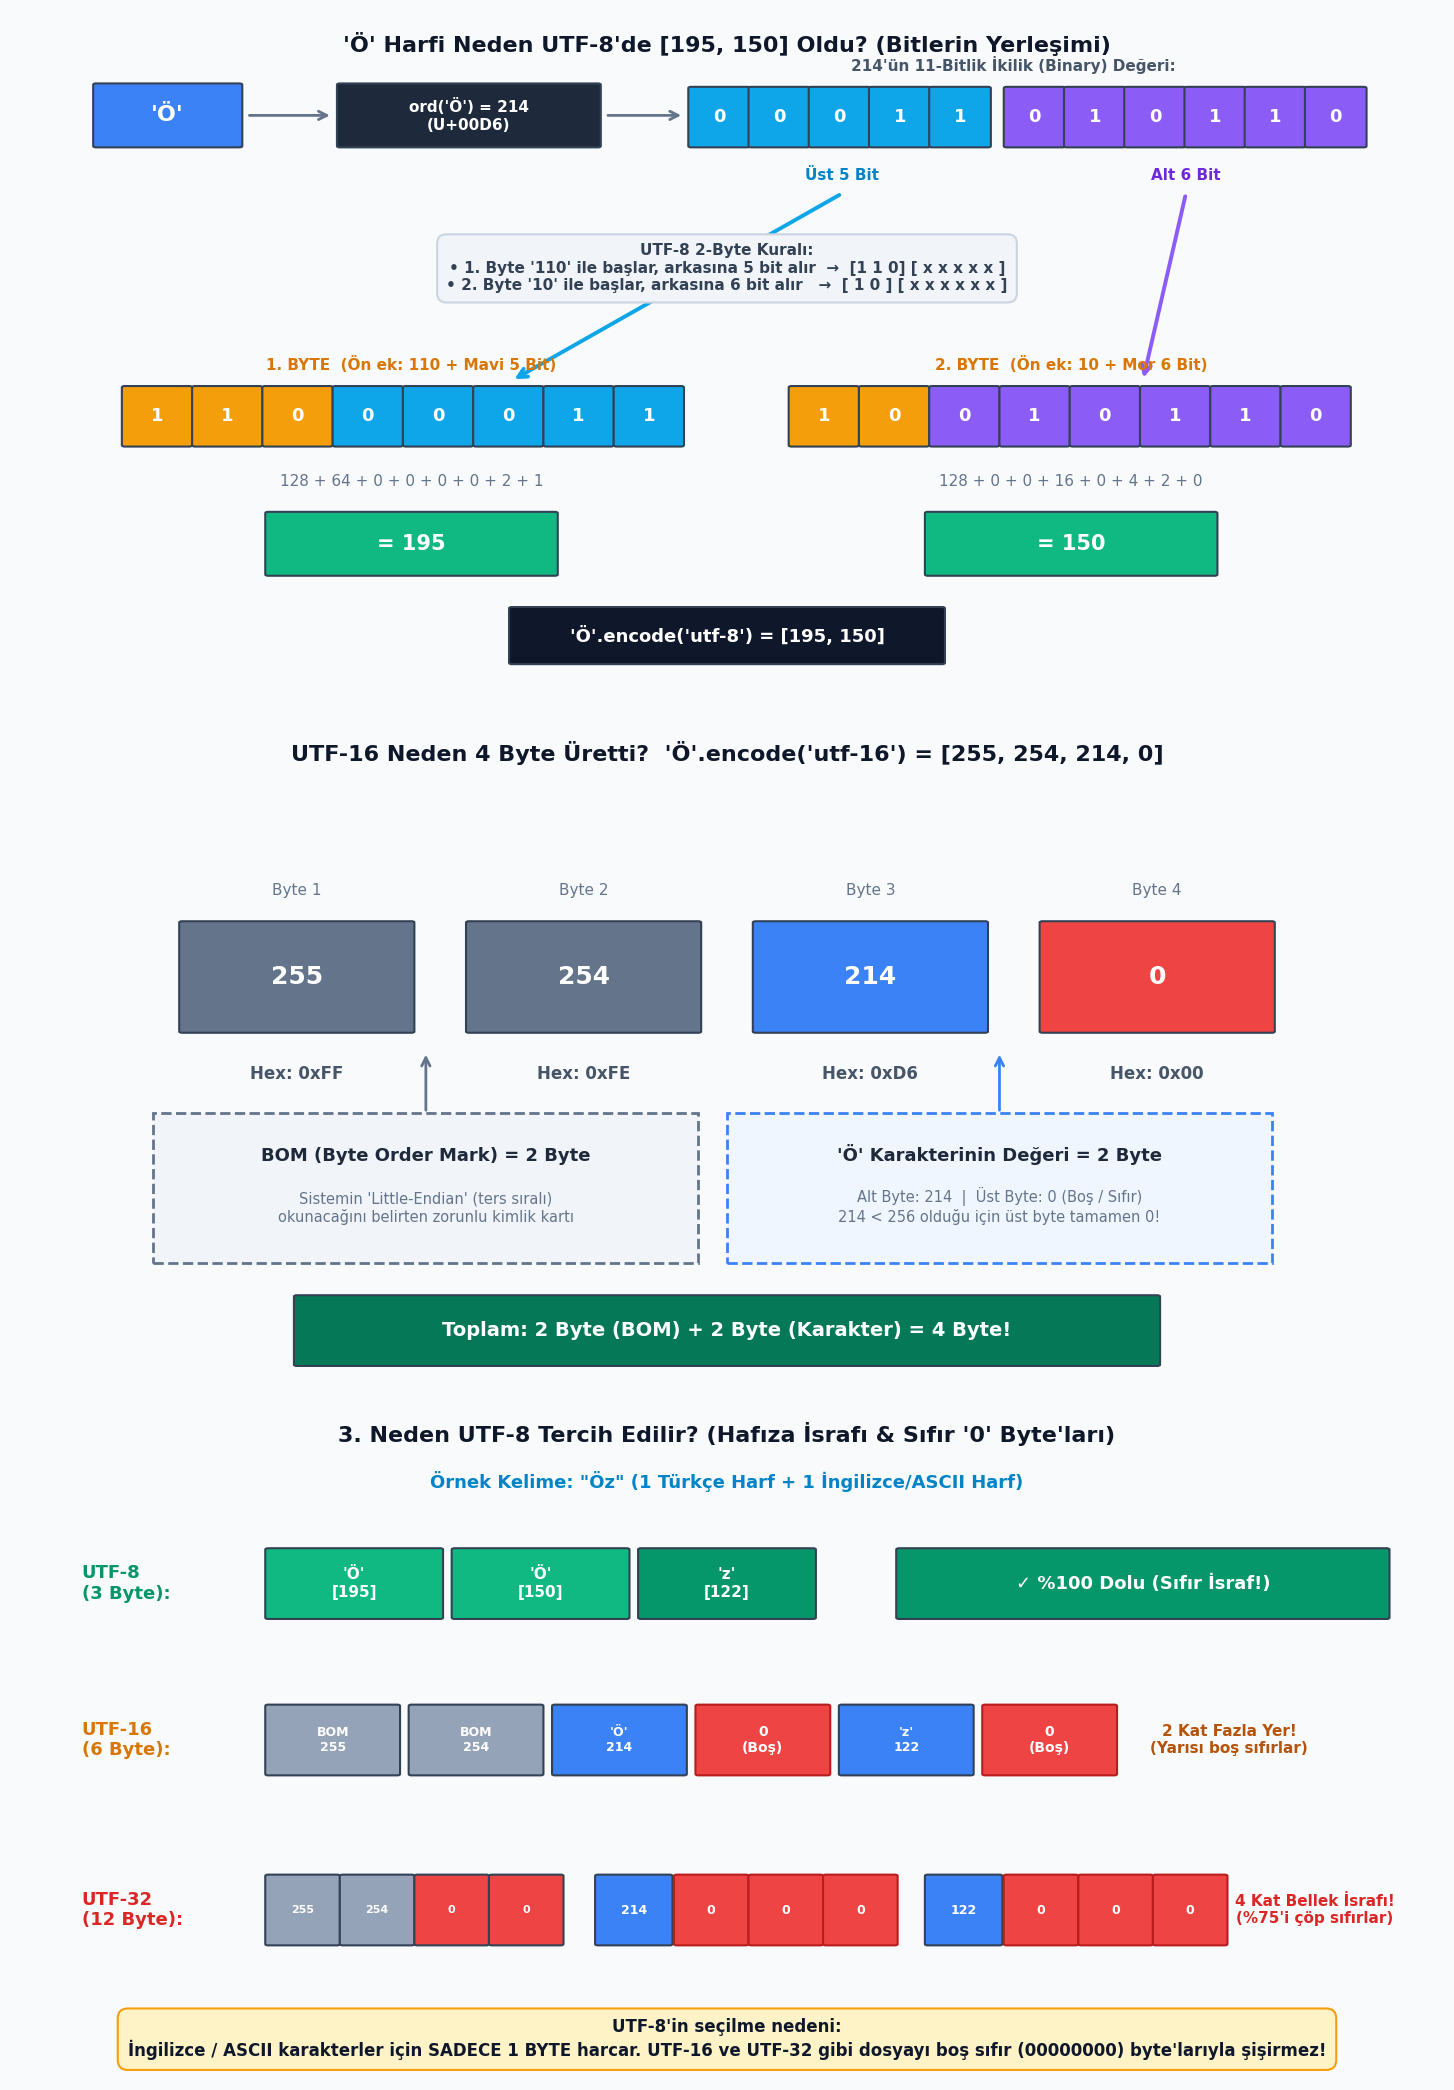

In [ ]:
# görselleştirme


import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Görsel genel ayarları
plt.rcParams['font.family'] = 'DejaVu Sans'
fig, axes = plt.subplots(3, 1, figsize=(15, 21), facecolor='#F8FAFC')

# ==============================================================================
# YARDIMCI ÇİZİM FONKSİYONLARI
# ==============================================================================
def draw_box(ax, x, y, w, h, text, color, text_color='white', fontsize=12, border='#334155', style='round,pad=0.2', zorder=2):
    rect = patches.FancyBboxPatch((x, y), w, h, boxstyle=style, facecolor=color, edgecolor=border, linewidth=1.5, zorder=zorder)
    ax.add_patch(rect)
    ax.text(x + w/2, y + h/2, text, ha='center', va='center', fontsize=fontsize, fontweight='bold', color=text_color, zorder=zorder+1)

def draw_arrow(ax, x1, y1, x2, y2, color='#64748B', style='->', lw=2, zorder=2):
    ax.annotate('', xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle=style, color=color, lw=lw, mutation_scale=15), zorder=zorder)

# ==============================================================================
# 1. BÖLÜM: 'Ö' (214) Neden UTF-8'de [195, 150] Oldu? (Bitlerin Yerleşimi)
# ==============================================================================
ax1 = axes[0]
ax1.set_xlim(0, 100)
ax1.set_ylim(0, 100)
ax1.axis('off')
ax1.set_facecolor('#F8FAFC')

# Başlık
ax1.text(50, 95, "'Ö' Harfi Neden UTF-8'de [195, 150] Oldu? (Bitlerin Yerleşimi)", 
         ha='center', va='center', fontsize=16, fontweight='bold', color='#0F172A', zorder=5)

# 1.1 Karakter ve Kod Noktası
draw_box(ax1, 6, 80, 10, 9, "'Ö'", '#3B82F6', fontsize=16, zorder=4)
draw_arrow(ax1, 16.5, 84.5, 22.5, 84.5, zorder=4)
draw_box(ax1, 23, 80, 18, 9, "ord('Ö') = 214\n(U+00D6)", '#1E293B', fontsize=11, zorder=4)
draw_arrow(ax1, 41.5, 84.5, 47, 84.5, zorder=4)

# 1.2 214'ün 11-Bitlik İkilik Değeri
ax1.text(70, 91, "214'ün 11-Bitlik İkilik (Binary) Değeri:", ha='center', fontsize=11, fontweight='bold', color='#475569', zorder=5)

# Üst 5 bit (Mavi - Byte 1'e gidecek)
bits_high = ['0', '0', '0', '1', '1']
for i, b in enumerate(bits_high):
    draw_box(ax1, 47.5 + i*4.2, 80, 3.9, 8.5, b, '#0EA5E9', fontsize=13, zorder=4)
ax1.text(58, 75, "Üst 5 Bit", ha='center', fontsize=11, color='#0284C7', fontweight='bold', zorder=5)

# Alt 6 bit (Mor - Byte 2'ye gidecek)
bits_low = ['0', '1', '0', '1', '1', '0']
for i, b in enumerate(bits_low):
    draw_box(ax1, 69.5 + i*4.2, 80, 3.9, 8.5, b, '#8B5CF6', fontsize=13, zorder=4)
ax1.text(82, 75, "Alt 6 Bit", ha='center', fontsize=11, color='#6D28D9', fontweight='bold', zorder=5)

# 1.3 UTF-8 Şablonu Kuralı (zorder=3: Okların üstünde yer alarak okları arkasından/altından geçirir)
template_box = (
    "UTF-8 2-Byte Kuralı:\n"
    "• 1. Byte '110' ile başlar, arkasına 5 bit alır  →  [1 1 0] [ x x x x x ]\n"
    "• 2. Byte '10' ile başlar, arkasına 6 bit alır   →  [ 1 0 ] [ x x x x x x ]"
)
ax1.text(50, 62, template_box, ha='center', va='center', fontsize=11, fontweight='bold', color='#334155',
         bbox=dict(boxstyle='round,pad=0.6', facecolor='#F1F5F9', edgecolor='#CBD5E1', lw=1.5), zorder=3)

# OKLAR (zorder=1: Tablonun altından / arkasından geçerek temiz bağlanır)
# Mavi Ok: "Üst 5 Bit" yazısından -> 1. BYTE mavi kısmına
ax1.annotate('', xy=(35, 45.5), xytext=(58, 73),
             arrowprops=dict(arrowstyle='->', color='#0EA5E9', lw=2.8, mutation_scale=16), zorder=1)

# Mor Ok: "Alt 6 Bit" yazısından -> 2. BYTE mor kısmına
ax1.annotate('', xy=(79, 45.5), xytext=(82, 73),
             arrowprops=dict(arrowstyle='->', color='#8B5CF6', lw=2.8, mutation_scale=16), zorder=1)

# 1.4 Oluşan Byte 1 (195)
ax1.text(28, 47, "1. BYTE  (Ön ek: 110 + Mavi 5 Bit)", ha='center', fontsize=11, fontweight='bold', color='#D97706', zorder=4)
byte1_bits = ['1', '1', '0', '0', '0', '0', '1', '1']
byte1_colors = ['#F59E0B', '#F59E0B', '#F59E0B', '#0EA5E9', '#0EA5E9', '#0EA5E9', '#0EA5E9', '#0EA5E9']
for i, (b, c) in enumerate(zip(byte1_bits, byte1_colors)):
    draw_box(ax1, 8 + i*4.9, 36, 4.5, 8.5, b, c, fontsize=13, zorder=4)

ax1.text(28, 30, "128 + 64 + 0 + 0 + 0 + 0 + 2 + 1", ha='center', fontsize=11, color='#64748B', zorder=4)
draw_box(ax1, 18, 17, 20, 9, "= 195", '#10B981', fontsize=15, zorder=4)

# 1.5 Oluşan Byte 2 (150)
ax1.text(74, 47, "2. BYTE  (Ön ek: 10 + Mor 6 Bit)", ha='center', fontsize=11, fontweight='bold', color='#D97706', zorder=4)
byte2_bits = ['1', '0', '0', '1', '0', '1', '1', '0']
byte2_colors = ['#F59E0B', '#F59E0B', '#8B5CF6', '#8B5CF6', '#8B5CF6', '#8B5CF6', '#8B5CF6', '#8B5CF6']
for i, (b, c) in enumerate(zip(byte2_bits, byte2_colors)):
    draw_box(ax1, 54.5 + i*4.9, 36, 4.5, 8.5, b, c, fontsize=13, zorder=4)

ax1.text(74, 30, "128 + 0 + 0 + 16 + 0 + 4 + 2 + 0", ha='center', fontsize=11, color='#64748B', zorder=4)
draw_box(ax1, 64, 17, 20, 9, "= 150", '#10B981', fontsize=15, zorder=4)

# Çıktı Rozeti
draw_box(ax1, 35, 4, 30, 8, "'Ö'.encode('utf-8') = [195, 150]", '#0F172A', fontsize=13, zorder=4)


# ==============================================================================
# 2. BÖLÜM: UTF-16 Neden 4 Byte Üretti?
# ==============================================================================
ax2 = axes[1]
ax2.set_xlim(0, 100)
ax2.set_ylim(0, 100)
ax2.axis('off')
ax2.set_facecolor('#F8FAFC')

# Başlık
ax2.text(50, 93, "UTF-16 Neden 4 Byte Üretti?  'Ö'.encode('utf-16') = [255, 254, 214, 0]", 
         ha='center', va='center', fontsize=16, fontweight='bold', color='#0F172A')

# 4 Byte Kutuları
utf16_vals = ['255', '254', '214', '0']
utf16_hex = ['0xFF', '0xFE', '0xD6', '0x00']
utf16_colors = ['#64748B', '#64748B', '#3B82F6', '#EF4444']

for i in range(4):
    x_pos = 12 + i*20
    draw_box(ax2, x_pos, 52, 16, 16, utf16_vals[i], utf16_colors[i], fontsize=18)
    ax2.text(x_pos + 8, 45, f"Hex: {utf16_hex[i]}", ha='center', fontsize=12, fontweight='bold', color='#475569')
    ax2.text(x_pos + 8, 72, f"Byte {i+1}", ha='center', fontsize=11, color='#64748B')

# BOM Açıklaması
rect_bom = patches.Rectangle((10, 18), 38, 22, linewidth=2, edgecolor='#64748B', facecolor='#F1F5F9', linestyle='--')
ax2.add_patch(rect_bom)
ax2.text(29, 33, "BOM (Byte Order Mark) = 2 Byte", ha='center', fontsize=13, fontweight='bold', color='#1E293B')
ax2.text(29, 24, "Sistemin 'Little-Endian' (ters sıralı)\nokunacağını belirten zorunlu kimlik kartı", ha='center', fontsize=10.5, color='#64748B')
draw_arrow(ax2, 29, 40, 29, 49, color='#64748B')

# Karakter Verisi Açıklaması
rect_char = patches.Rectangle((50, 18), 38, 22, linewidth=2, edgecolor='#3B82F6', facecolor='#EFF6FF', linestyle='--')
ax2.add_patch(rect_char)
ax2.text(69, 33, "'Ö' Karakterinin Değeri = 2 Byte", ha='center', fontsize=13, fontweight='bold', color='#1E293B')
ax2.text(69, 24, "Alt Byte: 214  |  Üst Byte: 0 (Boş / Sıfır)\n214 < 256 olduğu için üst byte tamamen 0!", ha='center', fontsize=10.5, color='#64748B')
draw_arrow(ax2, 69, 40, 69, 49, color='#3B82F6')

# Özet Formül
draw_box(ax2, 20, 3, 60, 10, "Toplam: 2 Byte (BOM) + 2 Byte (Karakter) = 4 Byte!", '#047857', fontsize=14)


# ==============================================================================
# 3. BÖLÜM: Neden UTF-8 Tercih Edilir? (İsraf / "0" Byte'ları Karşılaştırması)
# ==============================================================================
ax3 = axes[2]
ax3.set_xlim(0, 100)
ax3.set_ylim(0, 100)
ax3.axis('off')
ax3.set_facecolor('#F8FAFC')

# Başlık
ax3.text(50, 95, "3. Neden UTF-8 Tercih Edilir? (Hafıza İsrafı & Sıfır '0' Byte'ları)", 
         ha='center', va='center', fontsize=16, fontweight='bold', color='#0F172A')
ax3.text(50, 88, 'Örnek Kelime: "Öz" (1 Türkçe Harf + 1 İngilizce/ASCII Harf)', 
         ha='center', va='center', fontsize=13, fontweight='bold', color='#0284C7')

# UTF-8 Satırı
ax3.text(5, 73, "UTF-8\n(3 Byte):", fontsize=13, fontweight='bold', color='#059669', va='center')
draw_box(ax3, 18, 68, 12, 10, "'Ö'\n[195]", '#10B981', fontsize=11)
draw_box(ax3, 31, 68, 12, 10, "'Ö'\n[150]", '#10B981', fontsize=11)
draw_box(ax3, 44, 68, 12, 10, "'z'\n[122]", '#059669', fontsize=11)
draw_box(ax3, 62, 68, 34, 10, "✓ %100 Dolu (Sıfır İsraf!)", '#059669', fontsize=13)

# UTF-16 Satırı
ax3.text(5, 50, "UTF-16\n(6 Byte):", fontsize=13, fontweight='bold', color='#D97706', va='center')
draw_box(ax3, 18, 45, 9, 10, "BOM\n255", '#94A3B8', fontsize=9)
draw_box(ax3, 28, 45, 9, 10, "BOM\n254", '#94A3B8', fontsize=9)
draw_box(ax3, 38, 45, 9, 10, "'Ö'\n214", '#3B82F6', fontsize=9)
draw_box(ax3, 48, 45, 9, 10, "0\n(Boş)", '#EF4444', text_color='white', fontsize=10, border='#B91C1C')
draw_box(ax3, 58, 45, 9, 10, "'z'\n122", '#3B82F6', fontsize=9)
draw_box(ax3, 68, 45, 9, 10, "0\n(Boş)", '#EF4444', text_color='white', fontsize=10, border='#B91C1C')
ax3.text(85, 50, "2 Kat Fazla Yer!\n(Yarısı boş sıfırlar)", ha='center', va='center', fontsize=11, fontweight='bold', color='#B45309')

# UTF-32 Satırı
ax3.text(5, 25, "UTF-32\n(12 Byte):", fontsize=13, fontweight='bold', color='#DC2626', va='center')
# BOM (4 byte)
for idx, b_val in enumerate(['255', '254', '0', '0']):
    c_b = '#94A3B8' if idx < 2 else '#EF4444'
    draw_box(ax3, 18 + idx*5.2, 20, 4.8, 10, b_val, c_b, fontsize=8)

# 'Ö' (4 byte)
draw_box(ax3, 41, 20, 5, 10, "214", '#3B82F6', fontsize=9)
for idx in range(3):
    draw_box(ax3, 46.5 + idx*5.2, 20, 4.8, 10, "0", '#EF4444', text_color='white', fontsize=9, border='#B91C1C')

# 'z' (4 byte)
draw_box(ax3, 64, 20, 5, 10, "122", '#3B82F6', fontsize=9)
for idx in range(3):
    draw_box(ax3, 69.5 + idx*5.2, 20, 4.8, 10, "0", '#EF4444', text_color='white', fontsize=9, border='#B91C1C')

ax3.text(91, 25, "4 Kat Bellek İsrafı!\n(%75'i çöp sıfırlar)", ha='center', va='center', fontsize=11, fontweight='bold', color='#DC2626')

# Özet Banner
summary_text = (
    "UTF-8'in seçilme nedeni:\n"
    "İngilizce / ASCII karakterler için SADECE 1 BYTE harcar. "
    "UTF-16 ve UTF-32 gibi dosyayı boş sıfır (00000000) byte'larıyla şişirmez!"
)
ax3.text(50, 6, summary_text, ha='center', va='center', fontsize=12, fontweight='bold', color='#0F172A',
         bbox=dict(boxstyle='round,pad=0.6', facecolor='#FEF3C7', edgecolor='#F59E0B', linewidth=1.5))

plt.tight_layout()
plt.show()



In [4]:
# Görev 2: 
    ## BPE'yi sıfırdan yaz ve kendi Türkçe metninde eğit
            #### Geçen hafta derlediğin Türkçe metni kullan. 
        ### Ardışık ikilileri say
        ### En sık geçeni yeni bir token'la birleştir
        ### İstediğin vocab boyutuna gelene kadar tekrarla. 
    ## İlk 20 birleştirmeyi metin olarak yazdır: 
        ### Hangi harf grupları önce birleşiyor? 
        ### Sıkıştırma oranını (byte sayısı / token sayısı) yaz. 


# Türkçe metni okuduk ve UTF-8 byte'larına dönüştürdük
with open("input_tr.txt", "r", encoding="utf-8") as f:
    text = f.read()

tokens = list(text.encode("utf-8"))
original_byte_count = len(tokens)

# Başlangıç vocab (0-255 arası her byte'ın kendisi)
vocab = {idx: bytes([idx]) for idx in range(256)}

# BPE Fonksiyonları
def get_stats(ids):
    counts = {}
    for pair in zip(ids, ids[1:]):
        counts[pair] = counts.get(pair, 0) + 1
    return counts

def merge(ids, pair, idx):
    newids = []
    i = 0
    while i < len(ids):
        if i < len(ids) - 1 and ids[i] == pair[0] and ids[i+1] == pair[1]:
            newids.append(idx)
            i += 2
        else:
            newids.append(ids[i])
            i += 1
    return newids

# 4. İlk 20 Birleştirme (256 + 20 = 276)
vocab_size = 276
num_merges = vocab_size - 256
ids = list(tokens)

merges = {}
print("--- İLK 20 BİRLEŞTİRME (METİN OLARAK) ---")
for i in range(num_merges):
    stats = get_stats(ids)
    pair = max(stats, key=stats.get)
    idx = 256 + i
    ids = merge(ids, pair, idx)
    merges[pair] = idx

    # Birleştirilen token'ın metin (string) karşılığı
    vocab[idx] = vocab[pair[0]] + vocab[pair[1]]
    token_str = vocab[idx].decode("utf-8", errors="replace")
    
    print(f"{i+1:2d}. Birleştirme: {pair} -> Token {idx} | Metin: '{token_str}' (Frekans: {stats[pair]})")

# 5. Sıkıştırma Oranı Hesabı
final_token_count = len(ids)
compression_ratio = original_byte_count / final_token_count

print("\n--- SIKIŞTIRMA RAPORU ---")
print(f"Orijinal Byte Sayısı : {original_byte_count}")
print(f"BPE Sonrası Token    : {final_token_count}")
print(f"Sıkıştırma Oranı     : {compression_ratio:.3f}X (Byte / Token)")


--- İLK 20 BİRLEŞTİRME (METİN OLARAK) ---
 1. Birleştirme: (196, 177) -> Token 256 | Metin: 'ı' (Frekans: 34851)
 2. Birleştirme: (110, 32) -> Token 257 | Metin: 'n ' (Frekans: 18788)
 3. Birleştirme: (101, 32) -> Token 258 | Metin: 'e ' (Frekans: 17079)
 4. Birleştirme: (101, 114) -> Token 259 | Metin: 'er' (Frekans: 15666)
 5. Birleştirme: (97, 114) -> Token 260 | Metin: 'ar' (Frekans: 15393)
 6. Birleştirme: (195, 188) -> Token 261 | Metin: 'ü' (Frekans: 13759)
 7. Birleştirme: (197, 159) -> Token 262 | Metin: 'ş' (Frekans: 13125)
 8. Birleştirme: (105, 32) -> Token 263 | Metin: 'i ' (Frekans: 12148)
 9. Birleştirme: (97, 32) -> Token 264 | Metin: 'a ' (Frekans: 11643)
10. Birleştirme: (196, 159) -> Token 265 | Metin: 'ğ' (Frekans: 10381)
11. Birleştirme: (44, 32) -> Token 266 | Metin: ', ' (Frekans: 9130)
12. Birleştirme: (105, 108) -> Token 267 | Metin: 'il' (Frekans: 9100)
13. Birleştirme: (97, 110) -> Token 268 | Metin: 'an' (Frekans: 8367)
14. Birleştirme: (105, 110) -> Token 2

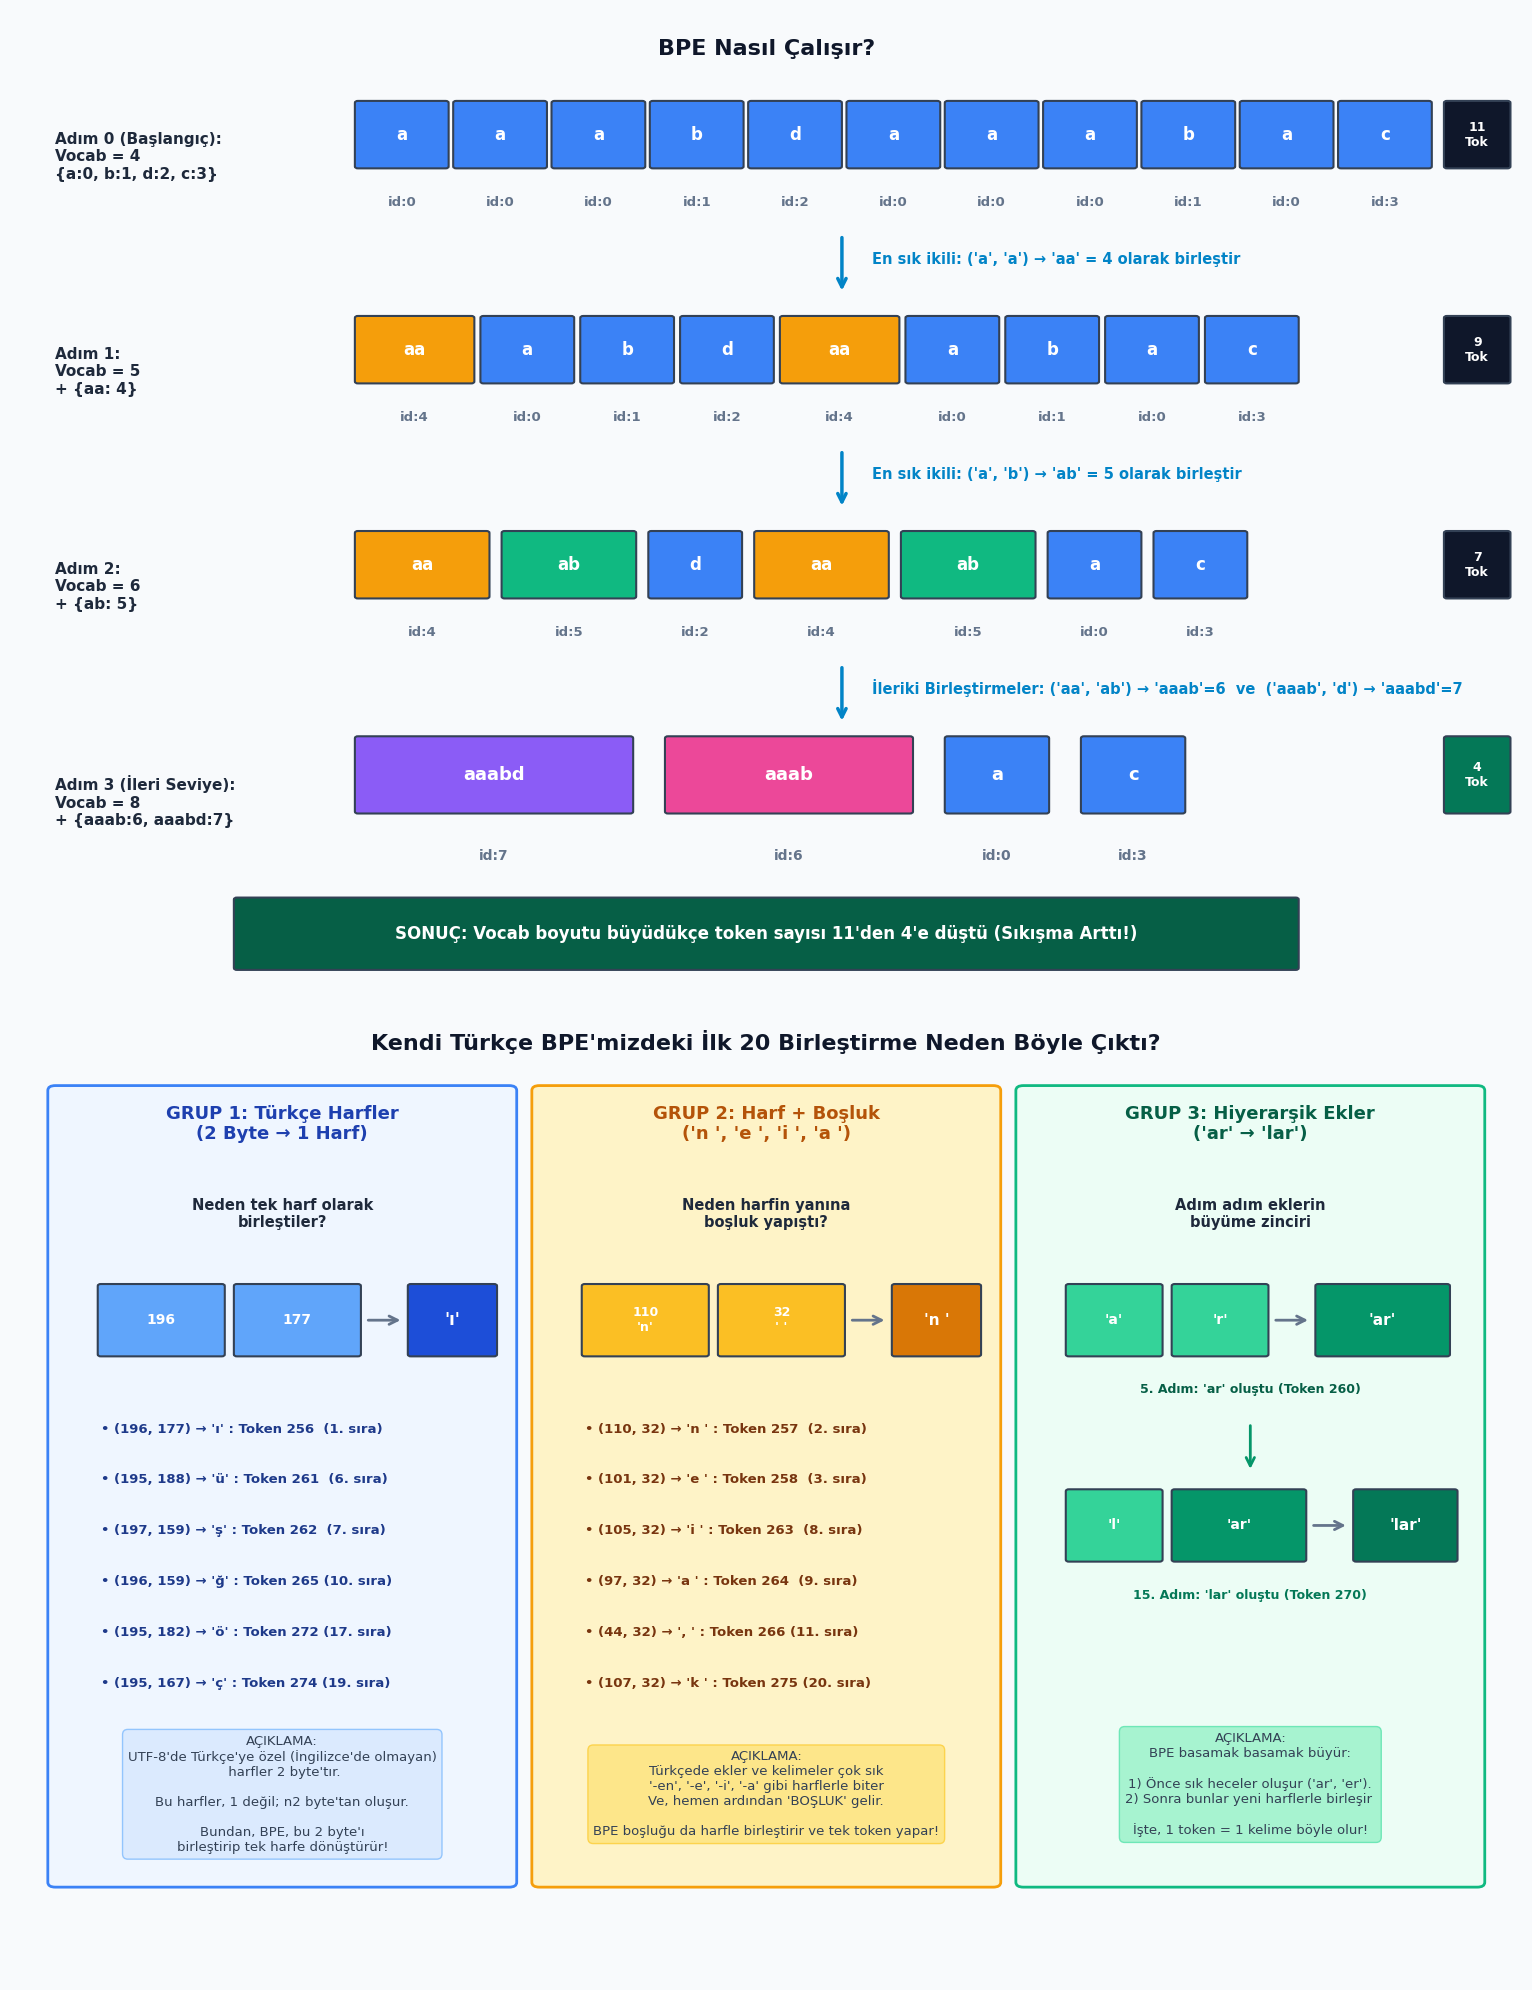

In [25]:
# görselleştirme


# BPE nedir - nasıl çalışır anlat
"""
Example
Suppose we are encoding the previous example of "aaabdaaabac", with a specified vocabulary size of 6, then it would first be encoded as "0, 0, 0, 1, 2, 0, 0, 0, 1, 0, 3" with a vocabulary of "a=0, b=1, d=2, c=3". Then it would proceed as before, and obtain "4, 5, 2, 4, 5, 0, 3" with a vocabulary of "a=0, b=1, d=2, c=3, aa=4, ab=5".

So far this is essentially the same as before. However, if we only had specified a vocabulary size of 5, then the process would stop at vocabulary "a=0, b=1, d=2, c=3, aa=4", so that the example would be encoded as "4, 0, 1, 2, 4, 0, 1, 0, 3". Conversely, if we had specified a vocabulary size of 8, then it would be encoded as "7, 6, 0, 3", with a vocabulary of "a=0, b=1, d=2, c=3, aa=4, ab=5, aaab=6, aaabd=7". This is not maximally compressed, because modified BPE does not aim for maximum compression. Instead, it aims for an encoding that is efficient and practical for language model training.[13]
"""

# sonuçlar neden böyle?
    ## ya tek harf (tek harf ise "ü,ö,ç" gibi türk alfabesi harfleri)
    ## ya da çift harf (bazısı tek harf değil, "harf+space char")


import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Görsel genel ayarları
plt.rcParams['font.family'] = 'DejaVu Sans'
fig, axes = plt.subplots(2, 1, figsize=(16, 20), facecolor='#F8FAFC')

# ==============================================================================
# YARDIMCI ÇİZİM FONKSİYONLARI
# ==============================================================================
def draw_box(ax, x, y, w, h, text, color, text_color='white', fontsize=11, border='#334155', style='round,pad=0.2', zorder=2):
    rect = patches.FancyBboxPatch((x, y), w, h, boxstyle=style, facecolor=color, edgecolor=border, linewidth=1.5, zorder=zorder)
    ax.add_patch(rect)
    ax.text(x + w/2, y + h/2, text, ha='center', va='center', fontsize=fontsize, fontweight='bold', color=text_color, zorder=zorder+1)

def draw_arrow(ax, x1, y1, x2, y2, color='#64748B', style='->', lw=2, zorder=2):
    ax.annotate('', xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle=style, color=color, lw=lw, mutation_scale=15), zorder=zorder)

# ==============================================================================
# 1. PANEL: BPE Adım Adım Nasıl Çalışır? ("aaabdaaabac" Örneği)
# ==============================================================================
ax1 = axes[0]
ax1.set_xlim(0, 100)
ax1.set_ylim(0, 100)
ax1.axis('off')
ax1.set_facecolor('#F8FAFC')

ax1.text(50, 96, 'BPE Nasıl Çalışır?',
         ha='center', va='center', fontsize=16, fontweight='bold', color='#0F172A')

# --- ADIM 0 (BAŞLANGIÇ: Vocab Size = 4) ---
ax1.text(3, 85, "Adım 0 (Başlangıç):\nVocab = 4\n{a:0, b:1, d:2, c:3}", fontsize=11, fontweight='bold', color='#1E293B', va='center')
chars_0 = ['a', 'a', 'a', 'b', 'd', 'a', 'a', 'a', 'b', 'a', 'c']
ids_0 =   ['0', '0', '0', '1', '2', '0', '0', '0', '1', '0', '3']
for i in range(11):
    draw_box(ax1, 23 + i*6.5, 84, 5.8, 6.5, chars_0[i], '#3B82F6', fontsize=12)
    ax1.text(23 + i*6.5 + 2.9, 80, f"id:{ids_0[i]}", ha='center', fontsize=9.5, color='#64748B', fontweight='bold')
draw_box(ax1, 95, 84, 4, 6.5, "11\nTok", '#0F172A', fontsize=9)

draw_arrow(ax1, 55, 77, 55, 71, color='#0284C7', lw=2.5)
ax1.text(57, 74, "En sık ikili: ('a', 'a') → 'aa' = 4 olarak birleştir", fontsize=10.5, fontweight='bold', color='#0284C7')

# --- ADIM 1 (Vocab Size = 5) ---
ax1.text(3, 63, "Adım 1:\nVocab = 5\n+ {aa: 4}", fontsize=11, fontweight='bold', color='#1E293B', va='center')
chars_1 = ['aa', 'a', 'b', 'd', 'aa', 'a', 'b', 'a', 'c']
ids_1 =   ['4',  '0', '1', '2', '4',  '0', '1', '0', '3']
colors_1 = ['#F59E0B', '#3B82F6', '#3B82F6', '#3B82F6', '#F59E0B', '#3B82F6', '#3B82F6', '#3B82F6', '#3B82F6']
x_cur = 23
for i in range(len(chars_1)):
    w = 7.5 if chars_1[i] == 'aa' else 5.8
    draw_box(ax1, x_cur, 62, w, 6.5, chars_1[i], colors_1[i], fontsize=12)
    ax1.text(x_cur + w/2, 58, f"id:{ids_1[i]}", ha='center', fontsize=9.5, color='#64748B', fontweight='bold')
    x_cur += w + 0.8
draw_box(ax1, 95, 62, 4, 6.5, "9\nTok", '#0F172A', fontsize=9)

draw_arrow(ax1, 55, 55, 55, 49, color='#0284C7', lw=2.5)
ax1.text(57, 52, "En sık ikili: ('a', 'b') → 'ab' = 5 olarak birleştir", fontsize=10.5, fontweight='bold', color='#0284C7')

# --- ADIM 2 (Vocab Size = 6) ---
ax1.text(3, 41, "Adım 2:\nVocab = 6\n+ {ab: 5}", fontsize=11, fontweight='bold', color='#1E293B', va='center')
chars_2 = ['aa', 'ab', 'd', 'aa', 'ab', 'a', 'c']
ids_2 =   ['4',  '5',  '2', '4',  '5',  '0', '3']
colors_2 = ['#F59E0B', '#10B981', '#3B82F6', '#F59E0B', '#10B981', '#3B82F6', '#3B82F6']
x_cur = 23
for i in range(len(chars_2)):
    w = 8.5 if len(chars_2[i]) == 2 else 5.8
    draw_box(ax1, x_cur, 40, w, 6.5, chars_2[i], colors_2[i], fontsize=12)
    ax1.text(x_cur + w/2, 36, f"id:{ids_2[i]}", ha='center', fontsize=9.5, color='#64748B', fontweight='bold')
    x_cur += w + 1.2
draw_box(ax1, 95, 40, 4, 6.5, "7\nTok", '#0F172A', fontsize=9)

draw_arrow(ax1, 55, 33, 55, 27, color='#0284C7', lw=2.5)
ax1.text(57, 30, "İleriki Birleştirmeler: ('aa', 'ab') → 'aaab'=6  ve  ('aaab', 'd') → 'aaabd'=7", fontsize=10.5, fontweight='bold', color='#0284C7')

# --- ADIM 3 (Vocab Size = 8) ---
ax1.text(3, 19, "Adım 3 (İleri Seviye):\nVocab = 8\n+ {aaab:6, aaabd:7}", fontsize=11, fontweight='bold', color='#1E293B', va='center')
chars_3 = ['aaabd', 'aaab', 'a', 'c']
ids_3 =   ['7',     '6',    '0', '3']
colors_3 = ['#8B5CF6', '#EC4899', '#3B82F6', '#3B82F6']
x_cur = 23
widths_3 = [18, 16, 6.5, 6.5]
for i in range(len(chars_3)):
    draw_box(ax1, x_cur, 18, widths_3[i], 7.5, chars_3[i], colors_3[i], fontsize=13)
    ax1.text(x_cur + widths_3[i]/2, 13, f"id:{ids_3[i]}", ha='center', fontsize=10, color='#64748B', fontweight='bold')
    x_cur += widths_3[i] + 2.5
draw_box(ax1, 95, 18, 4, 7.5, "4\nTok", '#047857', fontsize=9)

# Özet Kutu
draw_box(ax1, 15, 2, 70, 7, "SONUÇ: Vocab boyutu büyüdükçe token sayısı 11'den 4'e düştü (Sıkışma Arttı!)", '#065F46', fontsize=12)


# ==============================================================================
# 2. PANEL: Kendi BPE Sonuçlarımız Neden Böyle Çıktı? (3 Farklı Grup)
# ==============================================================================
ax2 = axes[1]
ax2.set_xlim(0, 100)
ax2.set_ylim(0, 100)
ax2.axis('off')
ax2.set_facecolor('#F8FAFC')

ax2.text(50, 96, "Kendi Türkçe BPE'mizdeki İlk 20 Birleştirme Neden Böyle Çıktı?",
         ha='center', va='center', fontsize=16, fontweight='bold', color='#0F172A')

# --- SÜTUN 1: TÜRKÇE HARFLERİN BİRLEŞMESİ (2 Byte -> 1 Harf) ---
rect_g1 = patches.FancyBboxPatch((3, 10), 30, 81, boxstyle='round,pad=0.5', facecolor='#EFF6FF', edgecolor='#3B82F6', lw=2)
ax2.add_patch(rect_g1)

ax2.text(18, 86, "GRUP 1: Türkçe Harfler\n(2 Byte → 1 Harf)", ha='center', fontsize=13, fontweight='bold', color='#1E40AF')
ax2.text(18, 77, "Neden tek harf olarak\nbirleştiler?", ha='center', fontsize=10.5, fontweight='bold', color='#1E293B')

# Örnek Çizim: 'ı' harfi
draw_box(ax2, 6, 64, 8, 7, "196", '#60A5FA', fontsize=10)
draw_box(ax2, 15, 64, 8, 7, "177", '#60A5FA', fontsize=10)
draw_arrow(ax2, 23.5, 67.5, 26, 67.5)
draw_box(ax2, 26.5, 64, 5.5, 7, "'ı'", '#1D4ED8', fontsize=12)

# Diğer örnekler listesi
tr_samples = [
    ("(196, 177)", "→ 'ı'", "Token 256  (1. sıra)"),
    ("(195, 188)", "→ 'ü'", "Token 261  (6. sıra)"),
    ("(197, 159)", "→ 'ş'", "Token 262  (7. sıra)"),
    ("(196, 159)", "→ 'ğ'", "Token 265 (10. sıra)"),
    ("(195, 182)", "→ 'ö'", "Token 272 (17. sıra)"),
    ("(195, 167)", "→ 'ç'", "Token 274 (19. sıra)")
]
for idx, (b_pair, ch, rank) in enumerate(tr_samples):
    ax2.text(6, 56 - idx*5.2, f"• {b_pair} {ch} : {rank}", fontsize=9.5, fontweight='bold', color='#1E3A8A')

desc_g1 = (
    "AÇIKLAMA:\n"
    "UTF-8'de Türkçe'ye özel (İngilizce'de olmayan)\n harfler 2 byte'tır.\n\n"
    "Bu harfler, 1 değil; n2 byte'tan oluşur.\n\n"
    "Bundan, BPE, bu 2 byte'ı\n"
    "birleştirip tek harfe dönüştürür!"
)
ax2.text(18, 19, desc_g1, ha='center', va='center', fontsize=9.5, color='#334155',
         bbox=dict(boxstyle='round,pad=0.4', facecolor='#DBEAFE', edgecolor='#93C5FD'))


# --- SÜTUN 2: HARF + BOŞLUK (Kelime Sonu Birleşmesi) ---
rect_g2 = patches.FancyBboxPatch((35, 10), 30, 81, boxstyle='round,pad=0.5', facecolor='#FEF3C7', edgecolor='#F59E0B', lw=2)
ax2.add_patch(rect_g2)

ax2.text(50, 86, "GRUP 2: Harf + Boşluk\n('n ', 'e ', 'i ', 'a ')", ha='center', fontsize=13, fontweight='bold', color='#B45309')
ax2.text(50, 77, "Neden harfin yanına\nboşluk yapıştı?", ha='center', fontsize=10.5, fontweight='bold', color='#1E293B')

# Örnek Çizim: 'n '
draw_box(ax2, 38, 64, 8, 7, "110\n'n'", '#FBBF24', fontsize=9)
draw_box(ax2, 47, 64, 8, 7, "32\n' '", '#FBBF24', fontsize=9)
draw_arrow(ax2, 55.5, 67.5, 58, 67.5)
draw_box(ax2, 58.5, 64, 5.5, 7, "'n '", '#D97706', fontsize=11)

space_samples = [
    ("(110, 32)", "→ 'n '", "Token 257  (2. sıra)"),
    ("(101, 32)", "→ 'e '", "Token 258  (3. sıra)"),
    ("(105, 32)", "→ 'i '", "Token 263  (8. sıra)"),
    ("(97, 32)",  "→ 'a '", "Token 264  (9. sıra)"),
    ("(44, 32)",  "→ ', '", "Token 266 (11. sıra)"),
    ("(107, 32)", "→ 'k '", "Token 275 (20. sıra)")
]
for idx, (b_pair, ch, rank) in enumerate(space_samples):
    ax2.text(38, 56 - idx*5.2, f"• {b_pair} {ch} : {rank}", fontsize=9.5, fontweight='bold', color='#78350F')

desc_g2 = (
    "AÇIKLAMA:\n"
    "Türkçede ekler ve kelimeler çok sık\n"
    "'-en', '-e', '-i', '-a' gibi harflerle biter\n"
    "Ve, hemen ardından 'BOŞLUK' gelir.\n\n"
    "BPE boşluğu da harfle birleştirir ve tek token yapar!"
)
ax2.text(50, 19, desc_g2, ha='center', va='center', fontsize=9.5, color='#334155',
         bbox=dict(boxstyle='round,pad=0.4', facecolor='#FDE68A', edgecolor='#FCD34D'))


# --- SÜTUN 3: HİYERARŞİK EKLER (Kök ve Eklerin Büyümesi) ---
rect_g3 = patches.FancyBboxPatch((67, 10), 30, 81, boxstyle='round,pad=0.5', facecolor='#ECFDF5', edgecolor='#10B981', lw=2)
ax2.add_patch(rect_g3)

ax2.text(82, 86, "GRUP 3: Hiyerarşik Ekler\n('ar' → 'lar')", ha='center', fontsize=13, fontweight='bold', color='#065F46')
ax2.text(82, 77, "Adım adım eklerin\nbüyüme zinciri", ha='center', fontsize=10.5, fontweight='bold', color='#1E293B')

# Zincir Gösterimi
draw_box(ax2, 70, 64, 6, 7, "'a'", '#34D399', fontsize=10)
draw_box(ax2, 77, 64, 6, 7, "'r'", '#34D399', fontsize=10)
draw_arrow(ax2, 83.5, 67.5, 86, 67.5)
draw_box(ax2, 86.5, 64, 8.5, 7, "'ar'", '#059669', fontsize=11)
ax2.text(82, 60, "5. Adım: 'ar' oluştu (Token 260)", ha='center', fontsize=9, fontweight='bold', color='#065F46')

draw_arrow(ax2, 82, 57, 82, 52, color='#059669', lw=2)

draw_box(ax2, 70, 43, 6, 7, "'l'", '#34D399', fontsize=10)
draw_box(ax2, 77, 43, 8.5, 7, "'ar'", '#059669', fontsize=10)
draw_arrow(ax2, 86, 46.5, 88.5, 46.5)
draw_box(ax2, 89, 43, 6.5, 7, "'lar'", '#047857', fontsize=11)
ax2.text(82, 39, "15. Adım: 'lar' oluştu (Token 270)", ha='center', fontsize=9, fontweight='bold', color='#047857')

desc_g3 = (
    "AÇIKLAMA:\n"
    "BPE basamak basamak büyür:\n\n"
    "1) Önce sık heceler oluşur ('ar', 'er').\n"
    "2) Sonra bunlar yeni harflerle birleşir \n\n"
    "İşte, 1 token = 1 kelime böyle olur!"
)
ax2.text(82, 20, desc_g3, ha='center', va='center', fontsize=9.5, color='#334155',
         bbox=dict(boxstyle='round,pad=0.4', facecolor='#A7F3D0', edgecolor='#6EE7B7'))

plt.tight_layout()
plt.show()


In [6]:
# Görev 3: 
    ## encode ve decode yaz. 
            #### decode(encode(metin)) metnin kendisini vermeli
        ### Türkçe karakterli ve emoji içeren bir örnekle göster
    ## Bazı token dizileri geçerli UTF-8 değil: "Decode bu durumda ne yapmalı, neden?" açıkla


vocab = {idx: bytes([idx]) for idx in range(256)}
for (p0, p1), idx in merges.items():
    vocab[idx] = vocab[p0] + vocab[p1]

def decode(ids):
  tokens = b"".join(vocab[idx] for idx in ids)
  text = tokens.decode("utf-8", errors="replace") # erros='replace' sayesinde "hatalı token dizisi" varsa çökmüyor porgram 
  return text

def encode(text):
  tokens = list(text.encode("utf-8"))
  while len(tokens) >= 2:
    stats = get_stats(tokens)
    pair = min(stats, key=lambda p: merges.get(p, float("inf")))
    if pair not in merges:
      break # nothing else can be merged
    idx = merges[pair]
    tokens = merge(tokens, pair, idx)
  return tokens


# --- TEST VE DOĞRULAMA (Türkçe Karakterler + Emojiler) ---
ornek = "Özün ışığı çağları aşar! 🚀🤖✨"

encoded_ids = encode(ornek)
decoded_text = decode(encoded_ids)

print("1. Orijinal Metin:")
print(ornek)

print("\n2. Encode Edilmiş Token ID'leri:")
print(encoded_ids)

print("\n3. Decode Edilmiş Metin:")
print(decoded_text)

# decode(encode(metin)) == metin kontrolü
assert decoded_text == ornek, "HATA: Decode sonucu orijinal metinle uyuşmuyor!"
print("\n✅ DOĞRULAMA BAŞARILI: decode(encode(metin)) birebir orijinal metni verdi!")


1. Orijinal Metin:
Özün ışığı çağları aşar! 🚀🤖✨

2. Encode Edilmiş Token ID'leri:
[195, 150, 122, 261, 257, 256, 262, 256, 265, 273, 274, 97, 265, 270, 273, 97, 262, 260, 33, 32, 240, 159, 154, 128, 240, 159, 164, 150, 226, 156, 168]

3. Decode Edilmiş Metin:
Özün ışığı çağları aşar! 🚀🤖✨

✅ DOĞRULAMA BAŞARILI: decode(encode(metin)) birebir orijinal metni verdi!


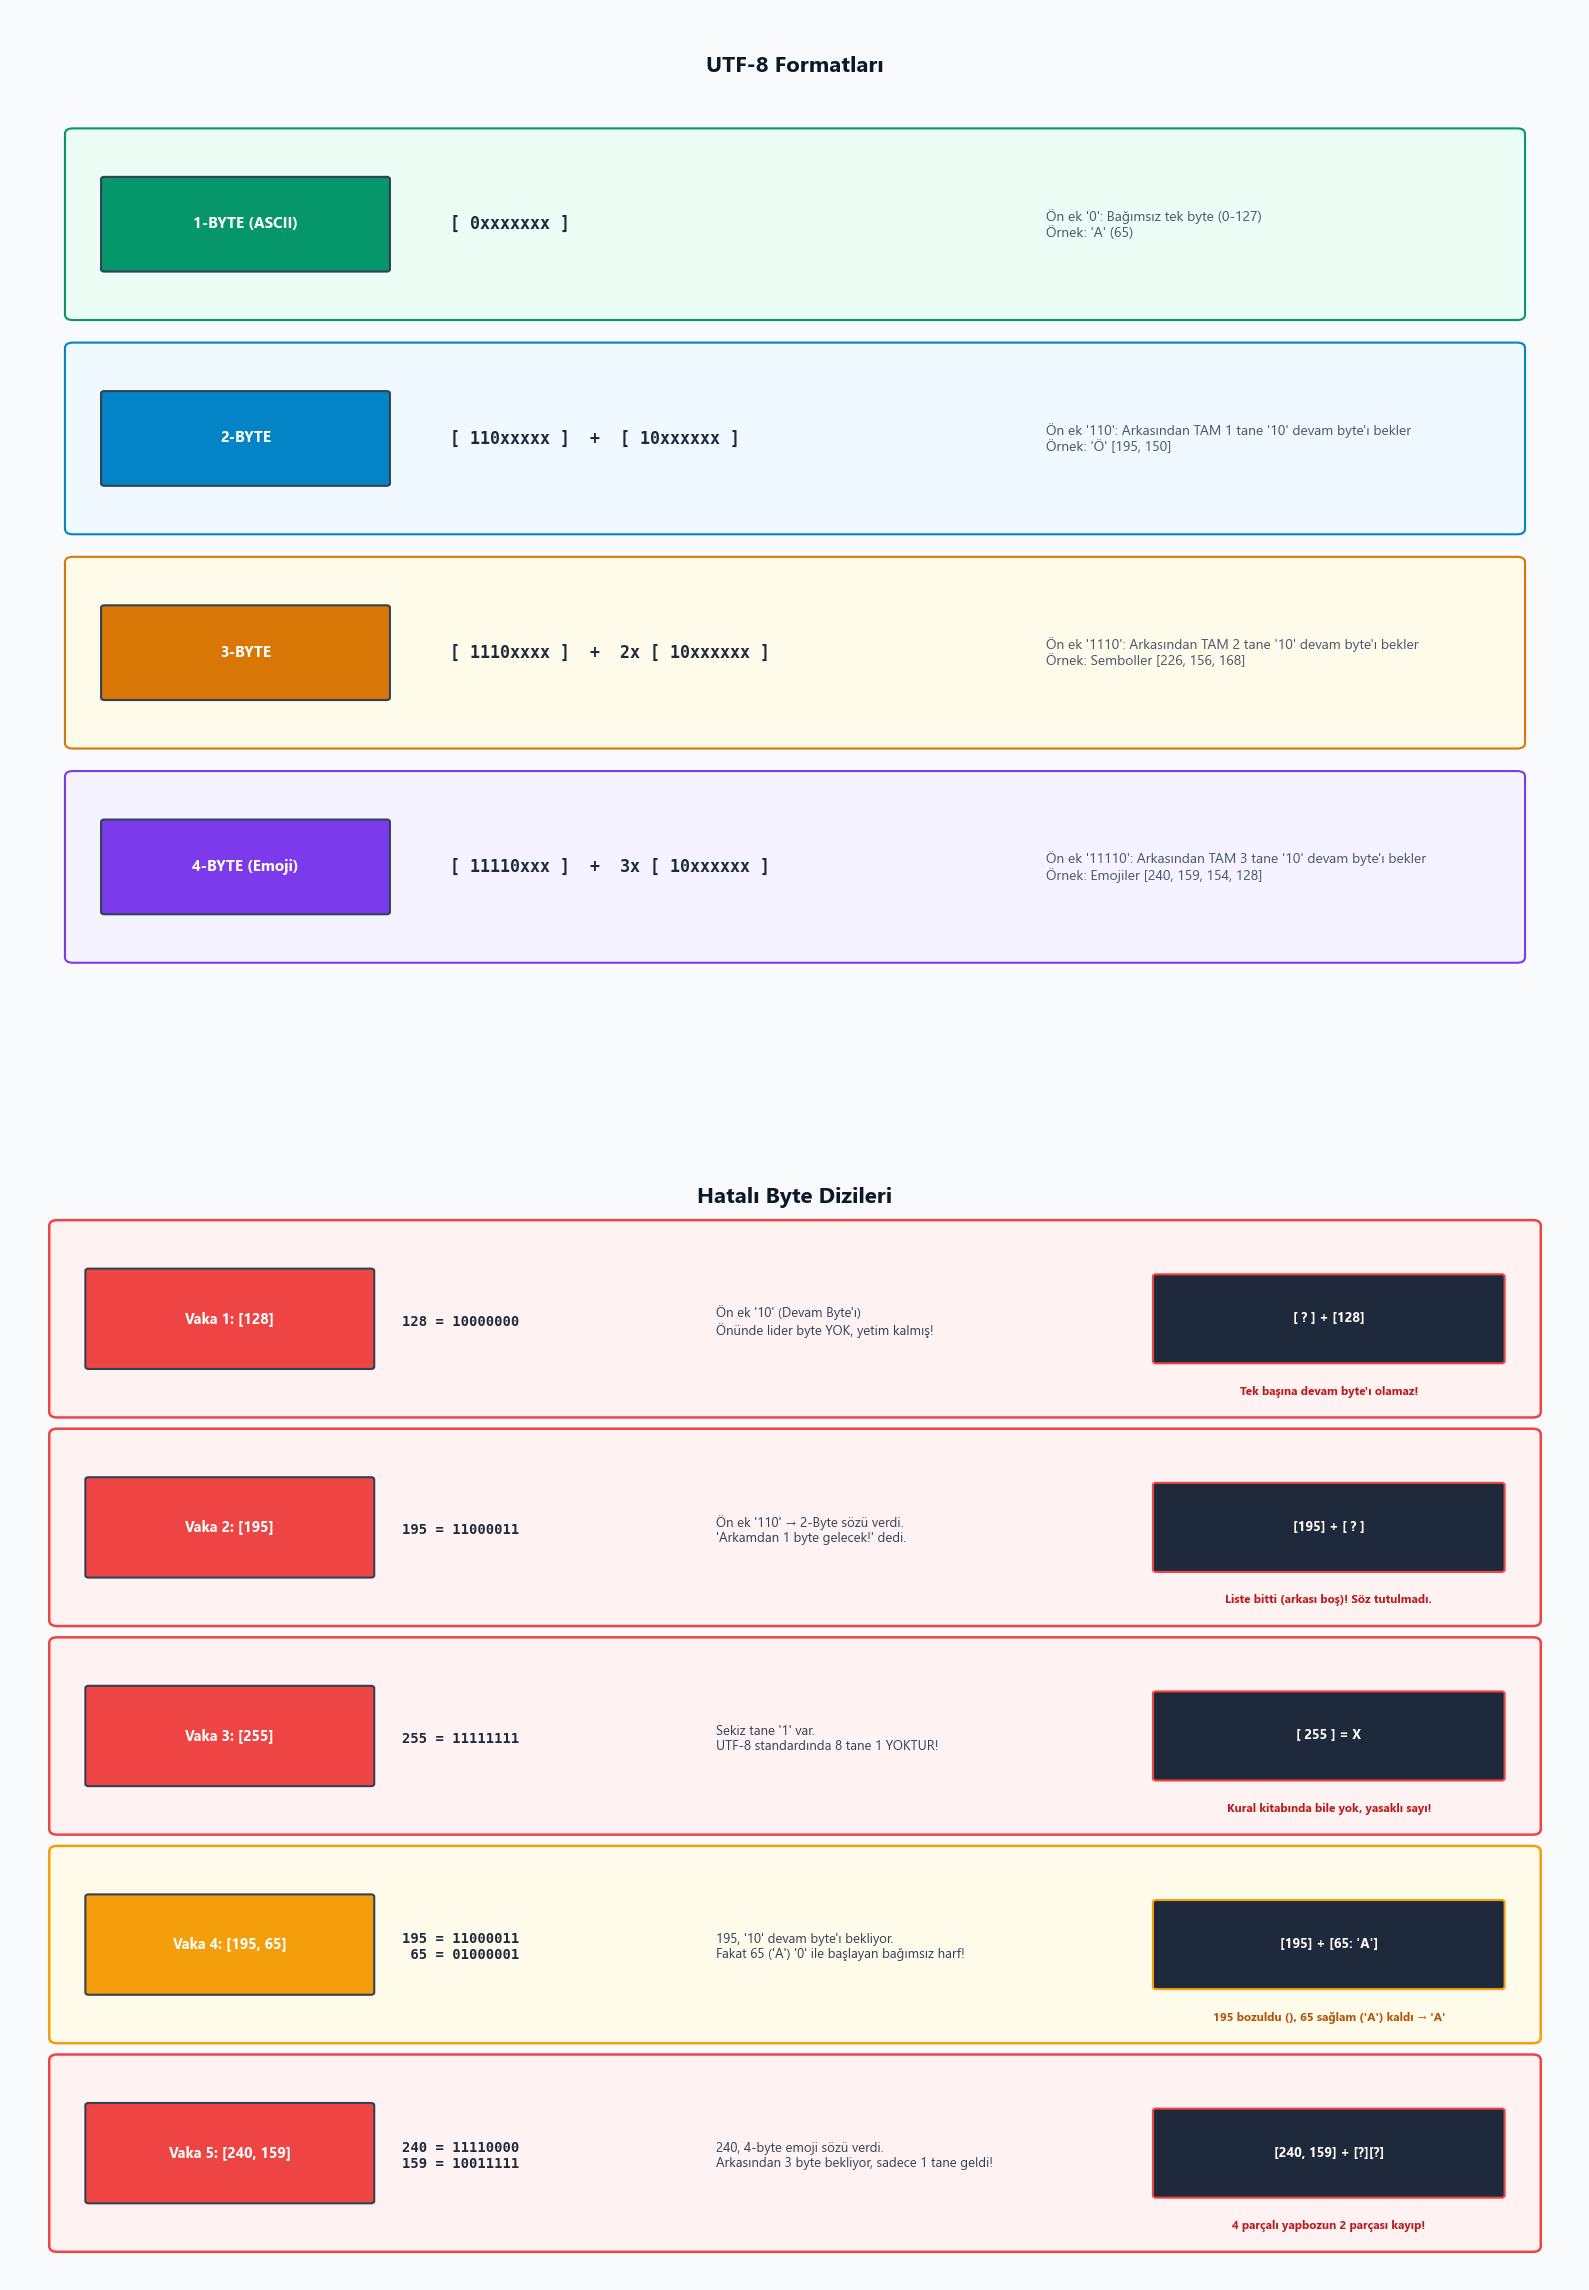

In [34]:
# görselleştirme

## bu açıklama şeysi, örnek üstünden olcak
    ### byte 1-2-3 representationları
    ### her bir örneğin nelerden dolayı bozdukları

import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Görsel genel ayarları
plt.rcParams['font.family'] = 'Segoe UI, DejaVu Sans, Arial'
fig, axes = plt.subplots(2, 1, figsize=(16, 23), facecolor='#F8FAFC')

# ==============================================================================
# YARDIMCI ÇİZİM FONKSİYONLARI
# ==============================================================================
def draw_box(ax, x, y, w, h, text, color, text_color='white', fontsize=11, border='#334155', style='round,pad=0.2', zorder=2):
    rect = patches.FancyBboxPatch((x, y), w, h, boxstyle=style, facecolor=color, edgecolor=border, linewidth=1.5, zorder=zorder)
    ax.add_patch(rect)
    ax.text(x + w/2, y + h/2, text, ha='center', va='center', fontsize=fontsize, fontweight='bold', color=text_color, zorder=zorder+1)

def draw_arrow(ax, x1, y1, x2, y2, color='#64748B', style='->', lw=2, zorder=2):
    ax.annotate('', xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle=style, color=color, lw=lw, mutation_scale=15), zorder=zorder)

# ==============================================================================
# 1. PANEL: UTF-8 Kural Kitabı (Altın Kural: Başlık Ne Söz Verdiyse O Gelir!)
# ==============================================================================
ax1 = axes[0]
ax1.set_xlim(0, 100)
ax1.set_ylim(0, 100)
ax1.axis('off')
ax1.set_facecolor('#F8FAFC')

ax1.text(50, 95, "UTF-8 Formatları",
         ha='center', va='center', fontsize=16, fontweight='bold', color='#0F172A')

templates = [
    ("1-BYTE (ASCII)", "[ 0xxxxxxx ]", "Ön ek '0': Bağımsız tek byte (0-127)\nÖrnek: 'A' (65)", '#059669', '#ECFDF5'),
    ("2-BYTE", "[ 110xxxxx ]  +  [ 10xxxxxx ]", "Ön ek '110': Arkasından TAM 1 tane '10' devam byte'ı bekler\nÖrnek: 'Ö' [195, 150]", '#0284C7', '#F0F9FF'),
    ("3-BYTE", "[ 1110xxxx ]  +  2x [ 10xxxxxx ]", "Ön ek '1110': Arkasından TAM 2 tane '10' devam byte'ı bekler\nÖrnek: Semboller [226, 156, 168]", '#D97706', '#FFFBEB'),
    ("4-BYTE (Emoji)", "[ 11110xxx ]  +  3x [ 10xxxxxx ]", "Ön ek '11110': Arkasından TAM 3 tane '10' devam byte'ı bekler\nÖrnek: Emojiler [240, 159, 154, 128]", '#7C3AED', '#F5F3FF')
]

for idx, (title, pattern, desc, color, bg) in enumerate(templates):
    y_pos = 73 - idx*19
    rect = patches.FancyBboxPatch((4, y_pos), 92, 16, boxstyle='round,pad=0.5', facecolor=bg, edgecolor=color, lw=1.5)
    ax1.add_patch(rect)
    
    draw_box(ax1, 6, y_pos + 4, 18, 8, title, color, fontsize=11)
    ax1.text(28, y_pos + 8, pattern, fontsize=12, fontweight='bold', color='#1E293B', va='center', family='monospace')
    ax1.text(66, y_pos + 8, desc, fontsize=10, color='#475569', va='center')


# ==============================================================================
# 2. PANEL: Neden Geçersiz? (5 Bozulma Vakası)
# ==============================================================================
ax2 = axes[1]
ax2.set_xlim(0, 100)
ax2.set_ylim(0, 100)
ax2.axis('off')
ax2.set_facecolor('#F8FAFC')

ax2.text(50, 96, "Hatalı Byte Dizileri",
         ha='center', va='center', fontsize=16, fontweight='bold', color='#0F172A')

cases = [
    # Vaka 1: [128]
    ("Vaka 1: [128]", "128 = 10000000", "Ön ek '10' (Devam Byte'ı)\nÖnünde lider byte YOK, yetim kalmış!",
     "[ ? ] + [128]", "Tek başına devam byte'ı olamaz!", '#EF4444'),
    # Vaka 2: [195]
    ("Vaka 2: [195]", "195 = 11000011", "Ön ek '110' → 2-Byte sözü verdi.\n'Arkamdan 1 byte gelecek!' dedi.",
     "[195] + [ ? ]", "Liste bitti (arkası boş)! Söz tutulmadı.", '#EF4444'),
    # Vaka 3: [255]
    ("Vaka 3: [255]", "255 = 11111111", "Sekiz tane '1' var.\nUTF-8 standardında 8 tane 1 YOKTUR!",
     "[ 255 ] = X", "Kural kitabında bile yok, yasaklı sayı!", '#EF4444'),
    # Vaka 4: [195, 65]
    ("Vaka 4: [195, 65]", "195 = 11000011\n 65 = 01000001", "195, '10' devam byte'ı bekliyor.\nFakat 65 ('A') '0' ile başlayan bağımsız harf!",
     "[195] + [65: 'A']", "195 bozuldu (), 65 sağlam ('A') kaldı → 'A'", '#F59E0B'),
    # Vaka 5: [240, 159]
    ("Vaka 5: [240, 159]", "240 = 11110000\n159 = 10011111", "240, 4-byte emoji sözü verdi.\nArkasından 3 byte bekliyor, sadece 1 tane geldi!",
     "[240, 159] + [?][?]", "4 parçalı yapbozun 2 parçası kayıp!", '#EF4444')
]

for idx, (title, b_val, problem, visual_tag, desc_tag, col) in enumerate(cases):
    y_pos = 77 - idx*18.5
    rect = patches.FancyBboxPatch((3, y_pos), 94, 16.5, boxstyle='round,pad=0.5', 
                                  facecolor='#FEF2F2' if col=='#EF4444' else '#FFFBEB',
                                  edgecolor=col, lw=1.8)
    ax2.add_patch(rect)
    
    # Başlık
    draw_box(ax2, 5, y_pos + 4, 18, 8.5, title, col, fontsize=10.5)
    
    # Binary
    ax2.text(25, y_pos + 8, b_val, fontsize=10, fontweight='bold', color='#1E293B', va='center', family='monospace')
    
    # Sorun açıklaması
    ax2.text(45, y_pos + 8, problem, fontsize=9.5, color='#334155', va='center')
    
    # Görsel Yapboz Kutusu
    draw_box(ax2, 73, y_pos + 4.5, 22, 7.5, visual_tag, '#1E293B', fontsize=9.5, border=col)
    ax2.text(84, y_pos + 1.5, desc_tag, ha='center', fontsize=8.5, color='#B91C1C' if col=='#EF4444' else '#B45309', fontweight='bold')



plt.tight_layout()
plt.show()

In [27]:
# Görev 4: 
    ## GPT-4'ün regex desenini ekle
    ## Metni:
        ### Önce GPT-4'ün deseniyle parçalara böl
        ### BPE'yi her parçada ayrı çalıştır
    ## Tokenizer'ı:
        ### Yeniden eğit
        ### Birleştirmeleri öncekiyle karşılaştır
        ### Sonra "Ankara'dan" ve "İstanbul'da" gibi kesme işaretli kelimeleri bu desenle böl
    ### Desen İngilizce için yazılmış: Türkçede ne yapıyor, kendi cümlelerinle yaz.


import regex as re


# GPT-4'ün Regex Deseni
GPT4_SPLIT_PATTERN = r"""'(?i:[sdmt]|ll|ve|re)|[^\r\n\p{L}\p{N}]?+\p{L}+|\p{N}{1,3}| ?[^\s\p{L}\p{N}]++[\r\n]*|\s*[\r\n]|\s+(?!\S)|\s+"""
gpt4_pat = re.compile(GPT4_SPLIT_PATTERN)

# Metni Desene Göre Parçalara Bölmek
text_chunks = re.findall(gpt4_pat, text)
ids_chunks = [list(ch.encode("utf-8")) for ch in text_chunks]

print(f"Toplam Parça (Chunk) Sayısı: {len(ids_chunks):,}")
print("İlk 5 Parça Örneği:", text_chunks[:5])

# BPE Train Fonksiyonları
def get_stats_chunks(chunks):
    counts = {}
    for chunk in chunks:
        for pair in zip(chunk, chunk[1:]):
            counts[pair] = counts.get(pair, 0) + 1
    return counts

def merge_chunks(chunks, pair, idx):
    return [merge(chunk, pair, idx) for chunk in chunks]

# Tokenizer'ı Regex Parçalarıyla Yeniden Eğit (İlk 20 Birleştirme)
vocab_size = 276
num_merges = vocab_size - 256
vocab_regex = {idx: bytes([idx]) for idx in range(256)}
merges_regex = {}

current_chunks = ids_chunks

print("\n--- GPT-4 REGEX İLE YENİ BİRLEŞTİRMELER ---")
for i in range(num_merges):
    stats = get_stats_chunks(current_chunks)
    pair = max(stats, key=stats.get)
    idx = 256 + i
    current_chunks = merge_chunks(current_chunks, pair, idx)
    merges_regex[pair] = idx

    vocab_regex[idx] = vocab_regex[pair[0]] + vocab_regex[pair[1]]
    token_str = vocab_regex[idx].decode("utf-8", errors="replace")
    print(f"{i+1:2d}. Birleştirme: {pair} -> Token {idx} | Metin: '{token_str}' (Frekans: {stats[pair]})")

# "Ankara'dan" ve "İstanbul'da" Testi
test_kelimeler = ["Ankara'dan", "İstanbul'da", "Türkiye'nin", "Ali'ye"]

print("\n--- TÜRKÇE KESME İŞARETLİ KELİME BÖLÜNME TESTİ ---")
for kelime in test_kelimeler:
    parcalar = re.findall(gpt4_pat, kelime)
    print(f"'{kelime}' -> Parçaları: {parcalar}")


Toplam Parça (Chunk) Sayısı: 161,805
İlk 5 Parça Örneği: ['Bir', ' varmış', ' bir', ' yokmuş', '.']

--- GPT-4 REGEX İLE YENİ BİRLEŞTİRMELER ---
 1. Birleştirme: (196, 177) -> Token 256 | Metin: 'ı' (Frekans: 34851)
 2. Birleştirme: (101, 114) -> Token 257 | Metin: 'er' (Frekans: 15666)
 3. Birleştirme: (97, 114) -> Token 258 | Metin: 'ar' (Frekans: 15393)
 4. Birleştirme: (105, 110) -> Token 259 | Metin: 'in' (Frekans: 13868)
 5. Birleştirme: (195, 188) -> Token 260 | Metin: 'ü' (Frekans: 13759)
 6. Birleştirme: (197, 159) -> Token 261 | Metin: 'ş' (Frekans: 13125)
 7. Birleştirme: (97, 110) -> Token 262 | Metin: 'an' (Frekans: 12282)
 8. Birleştirme: (32, 98) -> Token 263 | Metin: ' b' (Frekans: 11755)
 9. Birleştirme: (196, 159) -> Token 264 | Metin: 'ğ' (Frekans: 10381)
10. Birleştirme: (256, 110) -> Token 265 | Metin: 'ın' (Frekans: 9968)
11. Birleştirme: (100, 101) -> Token 266 | Metin: 'de' (Frekans: 9765)
12. Birleştirme: (105, 108) -> Token 267 | Metin: 'il' (Frekans: 9100)
13

### Regex Desenin Türkçe'deki Etkisi
* Desen, İngilizce diline uygun yapılmış
    - he'd (would)
    - they're (are)
    - i've (have)
    - it's (is)
    - i'm (am)
    - don't (not)
* Türkçe'ye aynısını uygulamayı deniyor - düzgün çalışmıyor
    - Ankara'dan -> "Ankara", "'d", "an"
    - Türkiye'miz -> "Türkiye", "'m", "iz"
    - Sinop'ta -> "Sinop", "'t", "a"

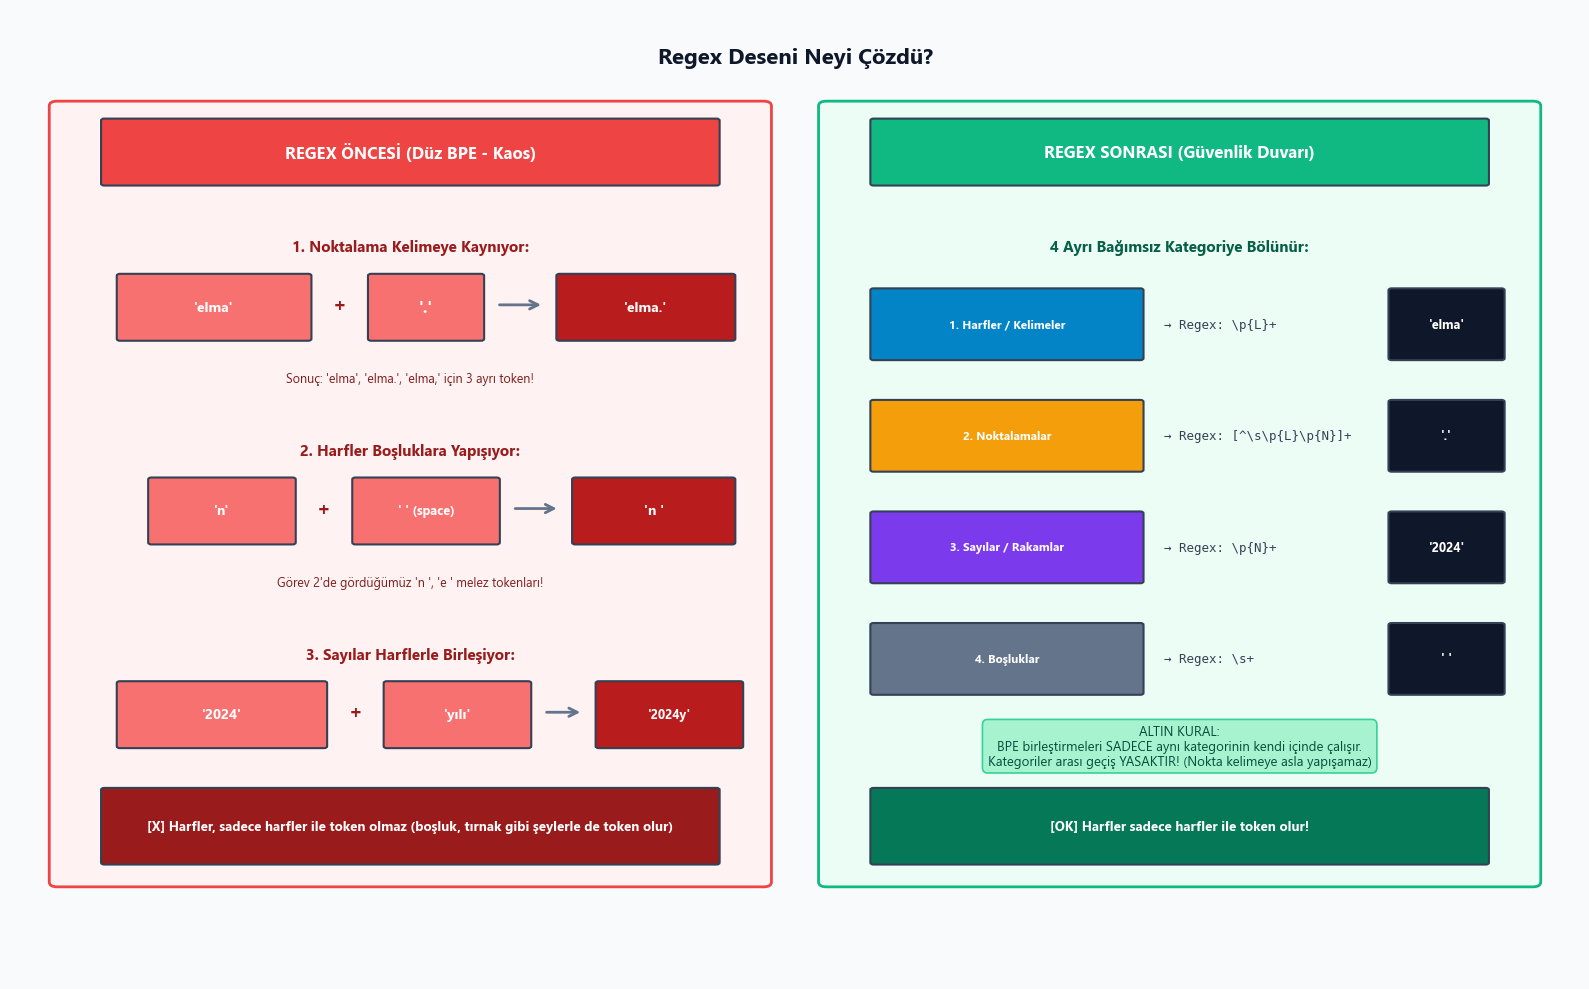

In [ ]:
# görselleştirme

import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Görsel genel ayarları
plt.rcParams['font.family'] = 'Segoe UI, DejaVu Sans, Arial'
fig, ax1 = plt.subplots(figsize=(16, 10), facecolor='#F8FAFC')

# ==============================================================================
# YARDIMCI ÇİZİM FONKSİYONLARI
# ==============================================================================
def draw_box(ax, x, y, w, h, text, color, text_color='white', fontsize=11, border='#334155', style='round,pad=0.2', zorder=2):
    rect = patches.FancyBboxPatch((x, y), w, h, boxstyle=style, facecolor=color, edgecolor=border, linewidth=1.5, zorder=zorder)
    ax.add_patch(rect)
    ax.text(x + w/2, y + h/2, text, ha='center', va='center', fontsize=fontsize, fontweight='bold', color=text_color, zorder=zorder+1)

def draw_arrow(ax, x1, y1, x2, y2, color='#64748B', style='->', lw=2, zorder=2):
    ax.annotate('', xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle=style, color=color, lw=lw, mutation_scale=15), zorder=zorder)

# ==============================================================================
# PANEL: Regex Öncesi vs Sonrası (Güvenlik Duvarı)
# ==============================================================================
ax1.set_xlim(0, 100)
ax1.set_ylim(0, 100)
ax1.axis('off')
ax1.set_facecolor('#F8FAFC')

ax1.text(50, 95, "Regex Deseni Neyi Çözdü?",
         ha='center', va='center', fontsize=16, fontweight='bold', color='#0F172A')

# --- SOL: REGEX YOK (DÜZ BPE - KAOS) ---
rect_left = patches.FancyBboxPatch((3, 10), 45, 80, boxstyle='round,pad=0.5', facecolor='#FEF2F2', edgecolor='#EF4444', lw=2)
ax1.add_patch(rect_left)

draw_box(ax1, 6, 82, 39, 6.5, "REGEX ÖNCESİ (Düz BPE - Kaos)", '#EF4444', fontsize=12)

# Sorun 1: Harf + Nokta Yapışması
ax1.text(25.5, 75, "1. Noktalama Kelimeye Kaynıyor:", ha='center', fontsize=11, fontweight='bold', color='#991B1B')
draw_box(ax1, 7, 66, 12, 6.5, "'elma'", '#F87171', fontsize=10)
ax1.text(21, 69.5, "+", fontsize=14, fontweight='bold', color='#991B1B', ha='center', va='center')
draw_box(ax1, 23, 66, 7, 6.5, "'.'", '#F87171', fontsize=12)
draw_arrow(ax1, 31, 69.5, 34, 69.5)
draw_box(ax1, 35, 66, 11, 6.5, "'elma.'", '#B91C1C', fontsize=10)
ax1.text(25.5, 61.5, "Sonuç: 'elma', 'elma.', 'elma,' için 3 ayrı token!", ha='center', fontsize=9, color='#7F1D1D')

# Sorun 2: Harf + Boşluk Yapışması
ax1.text(25.5, 54, "2. Harfler Boşluklara Yapışıyor:", ha='center', fontsize=11, fontweight='bold', color='#991B1B')
draw_box(ax1, 9, 45, 9, 6.5, "'n'", '#F87171', fontsize=10)
ax1.text(20, 48.5, "+", fontsize=14, fontweight='bold', color='#991B1B', ha='center', va='center')
draw_box(ax1, 22, 45, 9, 6.5, "' ' (space)", '#F87171', fontsize=9)
draw_arrow(ax1, 32, 48.5, 35, 48.5)
draw_box(ax1, 36, 45, 10, 6.5, "'n '", '#B91C1C', fontsize=10)
ax1.text(25.5, 40.5, "Görev 2'de gördüğümüz 'n ', 'e ' melez tokenları!", ha='center', fontsize=9, color='#7F1D1D')

# Sorun 3: Sayı + Harf Yapışması
ax1.text(25.5, 33, "3. Sayılar Harflerle Birleşiyor:", ha='center', fontsize=11, fontweight='bold', color='#991B1B')
draw_box(ax1, 7, 24, 13, 6.5, "'2024'", '#F87171', fontsize=10)
ax1.text(22, 27.5, "+", fontsize=14, fontweight='bold', color='#991B1B', ha='center', va='center')
draw_box(ax1, 24, 24, 9, 6.5, "'yılı'", '#F87171', fontsize=10)
draw_arrow(ax1, 34, 27.5, 36.5, 27.5)
draw_box(ax1, 37.5, 24, 9, 6.5, "'2024y'", '#B91C1C', fontsize=9)

# Kırmızı Özet
draw_box(ax1, 6, 12, 39, 7.5, "[X] Harfler, sadece harfler ile token olmaz (boşluk, tırnak gibi şeylerle de token olur)", '#991B1B', fontsize=9.5)


# --- SAĞ: REGEX SONRASI (GÜVENLİK DUVARI) ---
rect_right = patches.FancyBboxPatch((52, 10), 45, 80, boxstyle='round,pad=0.5', facecolor='#ECFDF5', edgecolor='#10B981', lw=2)
ax1.add_patch(rect_right)

draw_box(ax1, 55, 82, 39, 6.5, "REGEX SONRASI (Güvenlik Duvarı)", '#10B981', fontsize=12)

ax1.text(74.5, 75, "4 Ayrı Bağımsız Kategoriye Bölünür:", ha='center', fontsize=11, fontweight='bold', color='#065F46')

# 4 Kategori Duvarları
cat_boxes = [
    ("1. Harfler / Kelimeler", "\\p{L}+", "'elma'", '#0284C7'),
    ("2. Noktalamalar", "[^\\s\\p{L}\\p{N}]+", "'.'", '#F59E0B'),
    ("3. Sayılar / Rakamlar", "\\p{N}+", "'2024'", '#7C3AED'),
    ("4. Boşluklar", "\\s+", "' '", '#64748B')
]

for idx, (c_name, c_regex, c_ex, c_col) in enumerate(cat_boxes):
    y_b = 64 - idx*11.5
    draw_box(ax1, 55, y_b, 17, 7, c_name, c_col, fontsize=8.5)
    ax1.text(73.5, y_b + 3.5, f"→ Regex: {c_regex}", fontsize=9, color='#334155', va='center', family='monospace')
    draw_box(ax1, 88, y_b, 7, 7, c_ex, '#0F172A', fontsize=9)

# Duvar Kuralı
rule_desc = (
    "ALTIN KURAL:\n"
    "BPE birleştirmeleri SADECE aynı kategorinin kendi içinde çalışır.\n"
    "Kategoriler arası geçiş YASAKTIR! (Nokta kelimeye asla yapışamaz)"
)
ax1.text(74.5, 24, rule_desc, ha='center', va='center', fontsize=9.5, color='#064E3B',
         bbox=dict(boxstyle='round,pad=0.4', facecolor='#A7F3D0', edgecolor='#34D399', lw=1.2))

draw_box(ax1, 55, 12, 39, 7.5, "[OK] Harfler sadece harfler ile token olur!", '#047857', fontsize=9.5)

plt.tight_layout()
plt.show()

In [ ]:
# Görev 5: 
    ## Türkçe ile İngilizceyi karşılaştır
    ## Aynı paragrafın Türkçesini ve İngilizcesini al
    ## GPT-4'ün tokenizer'ıyla (tiktoken, "cl100k_base"):
        ### İkisini de token'la
        ### Kelime başına kaç token düştüğünü yaz
        ### Sonra aynı Türkçe paragrafı kendi tokenizer'ınla token'la. 
    ## "Türkçenin eklemeli yapısı bu sayıları nasıl etkiliyor?" açıkla


import tiktoken

# GPT-4 Tokenizer'ı
enc_gpt4 = tiktoken.get_encoding("cl100k_base")

# Türkçe ve İngilizce Paragraf (aynı anlamdaki)
tr_paragraf = (
    "Yapay zeka modelleri, insan dilinin karmaşık yapısını ve kültürel zenginliğini "
    "anlayabilmek için milyarlarca kelimeden oluşan devasa veri kümeleri üzerinde eğitilmektedir."
)

en_paragraf = (
    "Artificial intelligence models are trained on massive datasets consisting of "
    "billions of words to understand the complex structure and cultural richness of human language."
)

# Kelime Sayıları (Boşluklara göre)
tr_kelime_sayisi = len(tr_paragraf.split())
en_kelime_sayisi = len(en_paragraf.split())

# GPT-4 ile Tokenize Etmek
tr_tokens_gpt4 = enc_gpt4.encode(tr_paragraf)
en_tokens_gpt4 = enc_gpt4.encode(en_paragraf)

# Türkçe Paragrafı Tokenize Etmek
    ## (Görev 3'te yazdığımız encode fonksiyonunu kullanıyoruz)
tr_tokens_kendi = encode(tr_paragraf)

# İstatistikler
tr_gpt4_oran = len(tr_tokens_gpt4) / tr_kelime_sayisi
en_gpt4_oran = len(en_tokens_gpt4) / en_kelime_sayisi
tr_kendi_oran = len(tr_tokens_kendi) / tr_kelime_sayisi

# Rapor
print("=" * 65)
print(f"{'Model / Dil':<25} | {'Kelime':<8} | {'Token':<8} | {'Token/Kelime'}")
print("=" * 65)
print(f"{'GPT-4 (İngilizce)':<25} | {en_kelime_sayisi:<8} | {len(en_tokens_gpt4):<8} | {en_gpt4_oran:.2f}")
print(f"{'GPT-4 (Türkçe)':<25} | {tr_kelime_sayisi:<8} | {len(tr_tokens_gpt4):<8} | {tr_gpt4_oran:.2f}")
print(f"{'Kendi BPE (Türkçe)':<25} | {tr_kelime_sayisi:<8} | {len(tr_tokens_kendi):<8} | {tr_kendi_oran:.2f}")
print("=" * 65)

print("\n--- ÖRNEK TOKEN PARÇALANMASI (GPT-4) ---")
print("İngilizce İlk 3 Token:", [enc_gpt4.decode([t]) for t in en_tokens_gpt4[:20]])
print("Türkçe İlk 3 Token   :", [enc_gpt4.decode([t]) for t in tr_tokens_gpt4[:20]])


Model / Dil               | Kelime   | Token    | Token/Kelime
GPT-4 (İngilizce)         | 24       | 26       | 1.08
GPT-4 (Türkçe)            | 20       | 64       | 3.20
Kendi BPE (Türkçe)        | 20       | 135      | 6.75

--- ÖRNEK TOKEN PARÇALANMASI (GPT-4) ---
İngilizce İlk 3 Token: ['Art', 'ificial', ' intelligence', ' models', ' are', ' trained', ' on', ' massive', ' datasets', ' consisting', ' of', ' billions', ' of', ' words', ' to', ' understand', ' the', ' complex', ' structure', ' and']
Türkçe İlk 3 Token   : ['Y', 'ap', 'ay', ' z', 'eka', ' mod', 'eller', 'i', ',', ' insan', ' dil', 'inin', ' karma', 'ş', 'ık', ' yap', 'ıs', 'ını', ' ve', ' kü']


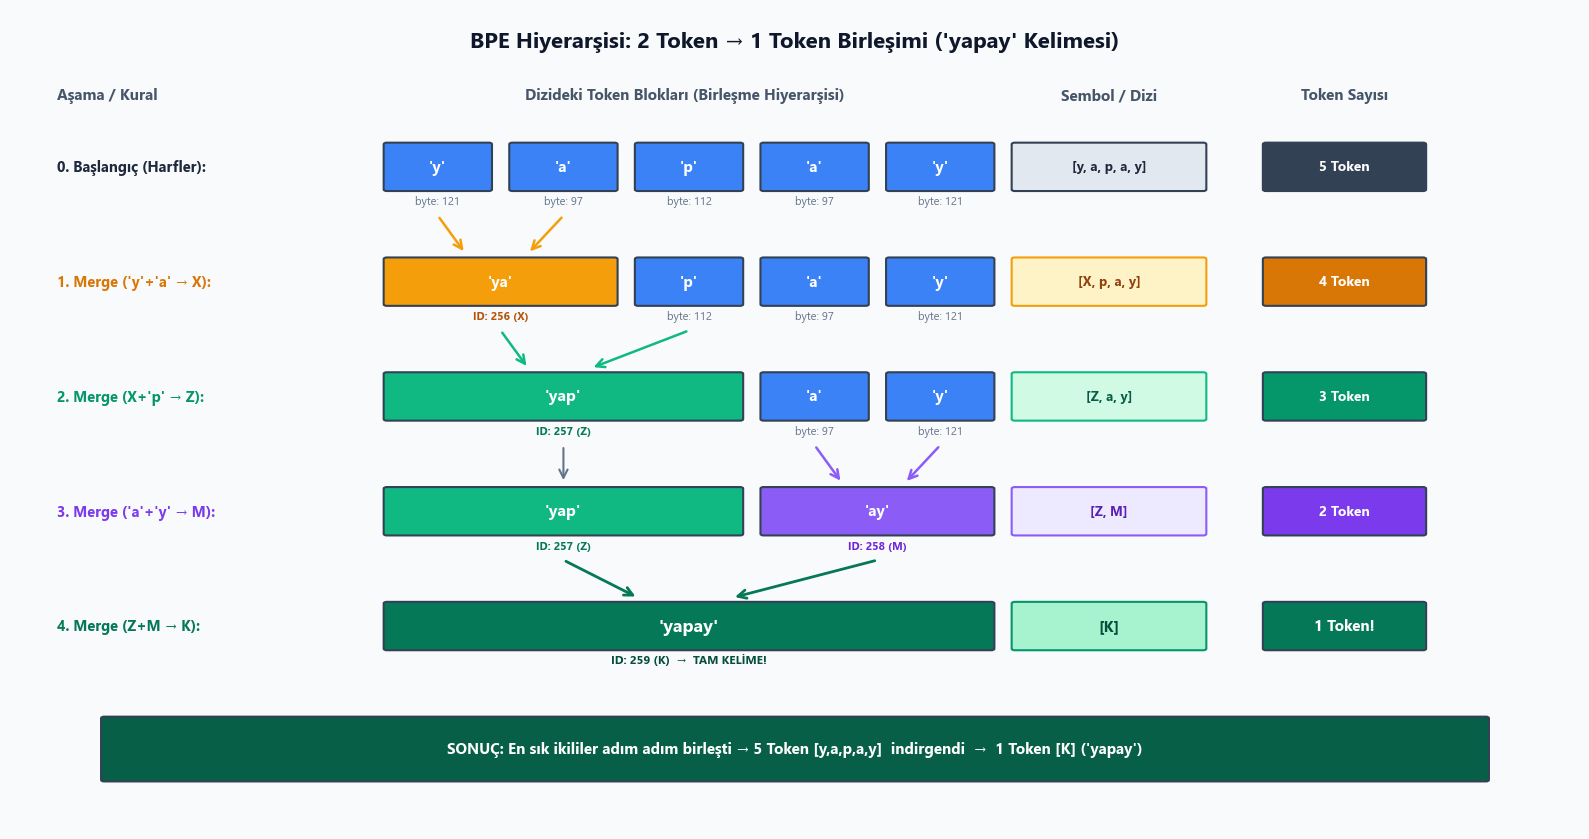

In [40]:
# görselleştirme

import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Font ve tuval ayarları
plt.rcParams['font.family'] = 'Segoe UI, DejaVu Sans, Arial'
fig, ax = plt.subplots(figsize=(16, 8.5), facecolor='#F8FAFC')

def draw_box(ax, x, y, w, h, text, color, text_color='white', fontsize=11, border='#334155', style='round,pad=0.2', zorder=2):
    rect = patches.FancyBboxPatch((x, y), w, h, boxstyle=style, facecolor=color, edgecolor=border, linewidth=1.5, zorder=zorder)
    ax.add_patch(rect)
    if text:
        ax.text(x + w/2, y + h/2, text, ha='center', va='center', fontsize=fontsize, fontweight='bold', color=text_color, zorder=zorder+1)
    return rect

def draw_arrow(ax, x1, y1, x2, y2, color='#64748B', style='->', lw=2, zorder=2):
    ax.annotate('', xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle=style, color=color, lw=lw, mutation_scale=15), zorder=zorder)

ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.axis('off')
ax.set_facecolor('#F8FAFC')

# Başlık
ax.text(50, 96, "BPE Hiyerarşisi: 2 Token → 1 Token Birleşimi ('yapay' Kelimesi)",
        ha='center', va='center', fontsize=16, fontweight='bold', color='#0F172A')

# Kolon Başlıkları
ax.text(3, 89, "Aşama / Kural", fontsize=11, fontweight='bold', color='#475569')
ax.text(43, 89, "Dizideki Token Blokları (Birleşme Hiyerarşisi)", ha='center', fontsize=11, fontweight='bold', color='#475569')
ax.text(70, 89, "Sembol / Dizi", ha='center', fontsize=11, fontweight='bold', color='#475569')
ax.text(85, 89, "Token Sayısı", ha='center', fontsize=11, fontweight='bold', color='#475569')

# Y Koordinatları
y_rows = [78, 64, 50, 36, 22]

# 0. ADIM: Başlangıç (Her harf 1 token)
y0 = y_rows[0]
ax.text(3, y0 + 2.7, "0. Başlangıç (Harfler):", fontsize=10.5, fontweight='bold', color='#1E293B', va='center')
chars = ["'y'", "'a'", "'p'", "'a'", "'y'"]
bytes_v = ["121", "97", "112", "97", "121"]
xs = [24, 32, 40, 48, 56]
for i, (ch, bv, x) in enumerate(zip(chars, bytes_v, xs)):
    draw_box(ax, x, y0, 6.5, 5.5, ch, '#3B82F6', fontsize=11)
    ax.text(x + 3.25, y0 - 1.8, f"byte: {bv}", ha='center', fontsize=8, color='#64748B')
draw_box(ax, 64, y0, 12, 5.5, "[y, a, p, a, y]", '#E2E8F0', text_color='#1E293B', fontsize=9.5)
draw_box(ax, 80, y0, 10, 5.5, "5 Token", '#334155', fontsize=10)

# Oklar: ('y' ve 'a' birleşiyor)
draw_arrow(ax, 27.25, y0 - 3.2, 29, y_rows[1] + 6.2, color='#F59E0B', lw=1.8)
draw_arrow(ax, 35.25, y0 - 3.2, 33, y_rows[1] + 6.2, color='#F59E0B', lw=1.8)

# 1. ADIM: 'y'+'a' -> X ('ya')
y1 = y_rows[1]
ax.text(3, y1 + 2.7, "1. Merge ('y'+'a' → X):", fontsize=10.5, fontweight='bold', color='#D97706', va='center')
draw_box(ax, 24, y1, 14.5, 5.5, "'ya'", '#F59E0B', fontsize=11)
ax.text(31.25, y1 - 1.8, "ID: 256 (X)", ha='center', fontsize=8, fontweight='bold', color='#B45309')
for ch, bv, x in [("'p'", "112", 40), ("'a'", "97", 48), ("'y'", "121", 56)]:
    draw_box(ax, x, y1, 6.5, 5.5, ch, '#3B82F6', fontsize=11)
    ax.text(x + 3.25, y1 - 1.8, f"byte: {bv}", ha='center', fontsize=8, color='#64748B')
draw_box(ax, 64, y1, 12, 5.5, "[X, p, a, y]", '#FEF3C7', text_color='#92400E', border='#F59E0B', fontsize=9.5)
draw_box(ax, 80, y1, 10, 5.5, "4 Token", '#D97706', fontsize=10)

# Oklar: (X ve 'p' birleşiyor)
draw_arrow(ax, 31.25, y1 - 3.2, 33, y_rows[2] + 6.2, color='#10B981', lw=1.8)
draw_arrow(ax, 43.25, y1 - 3.2, 37, y_rows[2] + 6.2, color='#10B981', lw=1.8)

# 2. ADIM: X+'p' -> Z ('yap')
y2 = y_rows[2]
ax.text(3, y2 + 2.7, "2. Merge (X+'p' → Z):", fontsize=10.5, fontweight='bold', color='#059669', va='center')
draw_box(ax, 24, y2, 22.5, 5.5, "'yap'", '#10B981', fontsize=11.5)
ax.text(35.25, y2 - 1.8, "ID: 257 (Z)", ha='center', fontsize=8, fontweight='bold', color='#047857')
for ch, bv, x in [("'a'", "97", 48), ("'y'", "121", 56)]:
    draw_box(ax, x, y2, 6.5, 5.5, ch, '#3B82F6', fontsize=11)
    ax.text(x + 3.25, y2 - 1.8, f"byte: {bv}", ha='center', fontsize=8, color='#64748B')
draw_box(ax, 64, y2, 12, 5.5, "[Z, a, y]", '#D1FAE5', text_color='#065F46', border='#10B981', fontsize=9.5)
draw_box(ax, 80, y2, 10, 5.5, "3 Token", '#059669', fontsize=10)

# Oklar: ('yap' iner, 'a'+'y' birleşir)
draw_arrow(ax, 35.25, y2 - 3.2, 35.25, y_rows[3] + 6.2, color='#64748B', lw=1.5)
draw_arrow(ax, 51.25, y2 - 3.2, 53, y_rows[3] + 6.2, color='#8B5CF6', lw=1.8)
draw_arrow(ax, 59.25, y2 - 3.2, 57, y_rows[3] + 6.2, color='#8B5CF6', lw=1.8)

# 3. ADIM: 'a'+'y' -> M ('ay')
y3 = y_rows[3]
ax.text(3, y3 + 2.7, "3. Merge ('a'+'y' → M):", fontsize=10.5, fontweight='bold', color='#7C3AED', va='center')
draw_box(ax, 24, y3, 22.5, 5.5, "'yap'", '#10B981', fontsize=11.5)
ax.text(35.25, y3 - 1.8, "ID: 257 (Z)", ha='center', fontsize=8, fontweight='bold', color='#047857')
draw_box(ax, 48, y3, 14.5, 5.5, "'ay'", '#8B5CF6', fontsize=11)
ax.text(55.25, y3 - 1.8, "ID: 258 (M)", ha='center', fontsize=8, fontweight='bold', color='#6D28D9')
draw_box(ax, 64, y3, 12, 5.5, "[Z, M]", '#EDE9FE', text_color='#5B21B6', border='#8B5CF6', fontsize=9.5)
draw_box(ax, 80, y3, 10, 5.5, "2 Token", '#7C3AED', fontsize=10)

# Oklar: (Z ve M birleşip K olur)
draw_arrow(ax, 35.25, y3 - 3.2, 40, y_rows[4] + 6.2, color='#047857', lw=2)
draw_arrow(ax, 55.25, y3 - 3.2, 46, y_rows[4] + 6.2, color='#047857', lw=2)

# 4. ADIM: Z+M -> K ('yapay')
y4 = y_rows[4]
ax.text(3, y4 + 2.7, "4. Merge (Z+M → K):", fontsize=10.5, fontweight='bold', color='#047857', va='center')
draw_box(ax, 24, y4, 38.5, 5.5, "'yapay'", '#047857', fontsize=13)
ax.text(43.25, y4 - 1.8, "ID: 259 (K)  →  TAM KELİME!", ha='center', fontsize=8.5, fontweight='bold', color='#064E3B')
draw_box(ax, 64, y4, 12, 5.5, "[K]", '#A7F3D0', text_color='#064E3B', border='#059669', fontsize=11)
draw_box(ax, 80, y4, 10, 5.5, "1 Token!", '#047857', fontsize=11)

# Alt Özet Barı
summary_bar = "SONUÇ: En sık ikililer adım adım birleşti → 5 Token [y,a,p,a,y]  indirgendi  →  1 Token [K] ('yapay')"
draw_box(ax, 6, 6, 88, 7.5, summary_bar, '#065F46', fontsize=11)

plt.tight_layout()
plt.show()

* sadece harf harf encode etsek, model hafızası dolar (encoding uzar)
* sadece kelime kelime enode etsek, vocab çok büyür (her 1 kelimeye 1 encoding yapsan.... çook kelime var)

### Türkçe'nin sondan eklemeli yapısı nasıl etkiliyor?
* Görselden de anladığmız gibi, "(birleşe birleşe) 1 token = 1 kelime" olması amacımız
* -> Olay: "Adım adım nasıl birleşebileceğini görebilmesi modelin"
    - 'Y', 'a', 'p', 'a', 'y' 
    - -> 'ya' 'p', 'a', 'y'
    - -> 'yap', 'a', 'y'
    - -> 'yap', 'ay'
    - -> 'yapay'
* -> Model, ekleri birleştirmeyi görüyor
* -> Görebilmesi için, "sık sık" o birleştirmelere rastlaması lazım
* -> (!!) Sorun da burda:
    - Türkçe, sondan eklemeli
    - Çok fazla, eklenebilecek olası ek var
    - Ondan, "sık olan birleştirmeleri görmek" daha zor
        * İngilizce'de ise çok daha az ek var - ondan öğrenmesi kolay
            - 'train' + 'ed' -> 'trained' gibi
            - (Bir tek "artificial"ı tam ayıramamış - onun dışında 1 kelime = 1 token)
            - Ama Türkçe'de neredeyse hiç "1 kelime = 1 token" yapamamış